## Real-World Interpretation of Synthetic Drift Types

**Sudden Drift:**  
Represents an abrupt change in the underlying data pattern, such as a sudden
lockdown, major outage, policy change, or extreme event that quickly changes
electricity demand.

**Gradual Drift:**  
Represents a change that develops progressively over time rather than occurring
at one instant, such as seasonal transitions or gradual changes in consumer
behaviour.

**Recurring Drift:**  
Represents a previously observed pattern returning after a period of different
behaviour, such as seasonal or recurring electricity-demand regimes.

**No Drift:**  
Represents a stable data-generating process. It is used as a control case to
check whether a detector raises false alarms when no actual drift exists.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Creat synthetic data using NumPy generator

In [5]:
import numpy as np

def make_series(kind="sudden", n=20000, noise=5, seed=42):
    """
    Generate a synthetic time series with known concept drift.

    Parameters
    ----------
    kind : str
        Type of drift:
        "sudden", "gradual", "recurring", or "no_drift"

    n : int
        Number of observations

    noise : float
        Standard deviation of random noise

    seed : int
        Random seed for reproducibility

    Returns
    -------
    y : np.ndarray
        Generated synthetic time series

    changepoints : list
        True changepoint indices
    """

    rng = np.random.default_rng(seed)

    # -------------------------------------------------
    # 1. SUDDEN DRIFT
    # A -> B -> C
    # -------------------------------------------------
    if kind == "sudden":

        cp1 = n // 3
        cp2 = 2 * n // 3

        part1 = rng.normal(100, noise, cp1)
        part2 = rng.normal(130, noise, cp2 - cp1)
        part3 = rng.normal(110, noise, n - cp2)

        y = np.concatenate([
            part1,
            part2,
            part3
        ])

        changepoints = [cp1, cp2]

    # -------------------------------------------------
    # 2. GRADUAL DRIFT
    # Slowly changes from A -> B
    # -------------------------------------------------
    elif kind == "gradual":

        cp1 = n // 3
        cp2 = 2 * n // 3

        # Stable first regime
        part1 = rng.normal(100, noise, cp1)

        # Gradually move the mean from 100 to 130
        gradual_length = cp2 - cp1

        gradual_mean = np.linspace(
            100,
            130,
            gradual_length
        )

        part2 = gradual_mean + rng.normal(
            0,
            noise,
            gradual_length
        )

        # Stable new regime
        part3 = rng.normal(
            130,
            noise,
            n - cp2
        )

        y = np.concatenate([
            part1,
            part2,
            part3
        ])

        # These represent the start and end
        # of the gradual transition
        changepoints = [cp1, cp2]

    # -------------------------------------------------
    # 3. RECURRING DRIFT
    # A -> B -> A -> B -> A
    # -------------------------------------------------
    elif kind == "recurring":

        section = n // 5

        part1 = rng.normal(100, noise, section)  # A
        part2 = rng.normal(130, noise, section)  # B
        part3 = rng.normal(100, noise, section)  # A returns
        part4 = rng.normal(130, noise, section)  # B returns

        # Handles any leftover observations if n
        # is not exactly divisible by 5
        part5 = rng.normal(
            100,
            noise,
            n - 4 * section
        )

        y = np.concatenate([
            part1,
            part2,
            part3,
            part4,
            part5
        ])

        changepoints = [
            section,
            2 * section,
            3 * section,
            4 * section
        ]

    # -------------------------------------------------
    # 4. NO DRIFT
    # Same distribution for the whole stream
    # -------------------------------------------------
    elif kind == "no_drift":

        y = rng.normal(
            100,
            noise,
            n
        )

        changepoints = []

    # -------------------------------------------------
    # Invalid input
    # -------------------------------------------------
    else:

        raise ValueError(
            "kind must be 'sudden', 'gradual', "
            "'recurring', or 'no_drift'"
        )

    return y, changepoints

In [6]:
y_sudden, cp_sudden = make_series(
    kind="sudden",
    n=20000,
    noise=5
)

y_gradual, cp_gradual = make_series(
    kind="gradual",
    n=20000,
    noise=5
)

y_recurring, cp_recurring = make_series(
    kind="recurring",
    n=20000,
    noise=5
)

y_no_drift, cp_no_drift = make_series(
    kind="no_drift",
    n=20000,
    noise=5
)

print("Sudden:", cp_sudden)
print("Gradual:", cp_gradual)
print("Recurring:", cp_recurring)
print("No drift:", cp_no_drift)

Sudden: [6666, 13333]
Gradual: [6666, 13333]
Recurring: [4000, 8000, 12000, 16000]
No drift: []


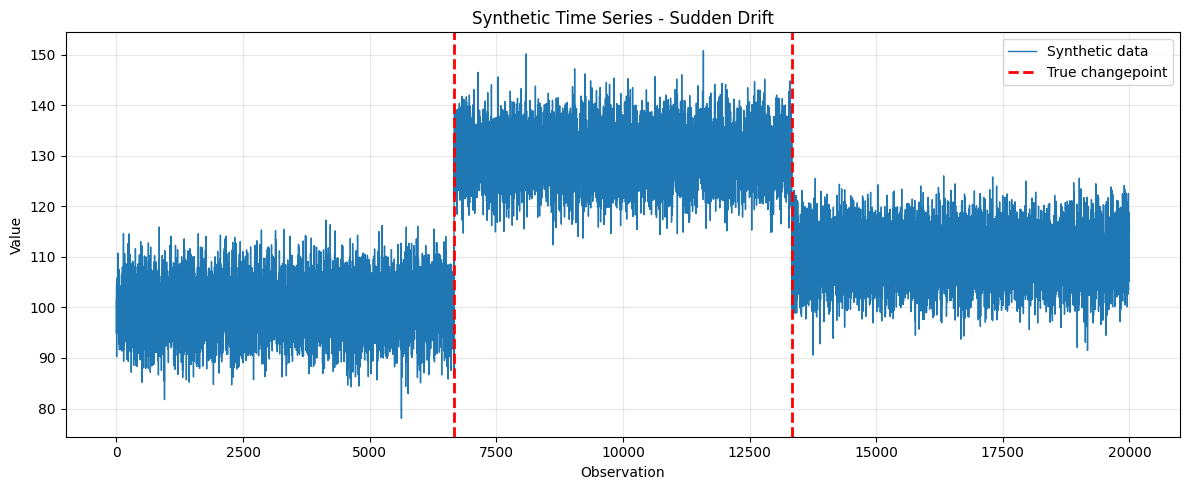

In [7]:
# NUMPY SYNTHETIC BENCHMARK - SUDDEN DRIFT
# Plot the synthetic series with the known true changepoints

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Synthetic sudden-drift series
plt.plot(
    y_sudden,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_sudden):
    plt.axvline(
        x=cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

plt.title("Synthetic Time Series - Sudden Drift")
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

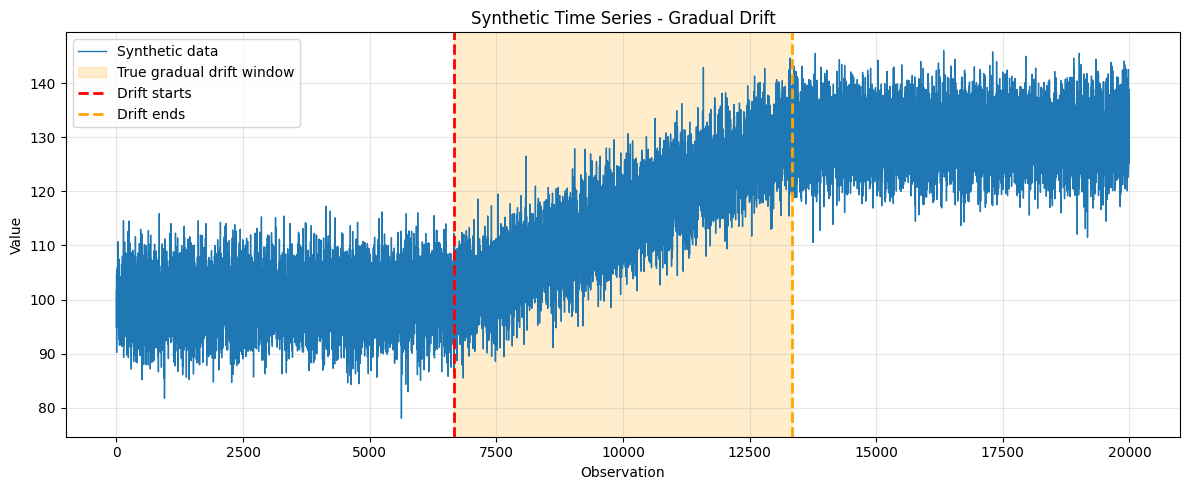

In [8]:
plt.figure(figsize=(12, 5))

# Plot the synthetic series
plt.plot(
    y_gradual,
    linewidth=1,
    label="Synthetic data"
)

# Start and end of the gradual drift
drift_start = cp_gradual[0]
drift_end = cp_gradual[1]

# Shade the complete gradual transition window
plt.axvspan(
    drift_start,
    drift_end,
    alpha=0.2,
    color="orange",
    label="True gradual drift window"
)

# Mark the start
plt.axvline(
    x=drift_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Drift starts"
)

# Mark the end
plt.axvline(
    x=drift_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Drift ends"
)

plt.title("Synthetic Time Series - Gradual Drift")
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

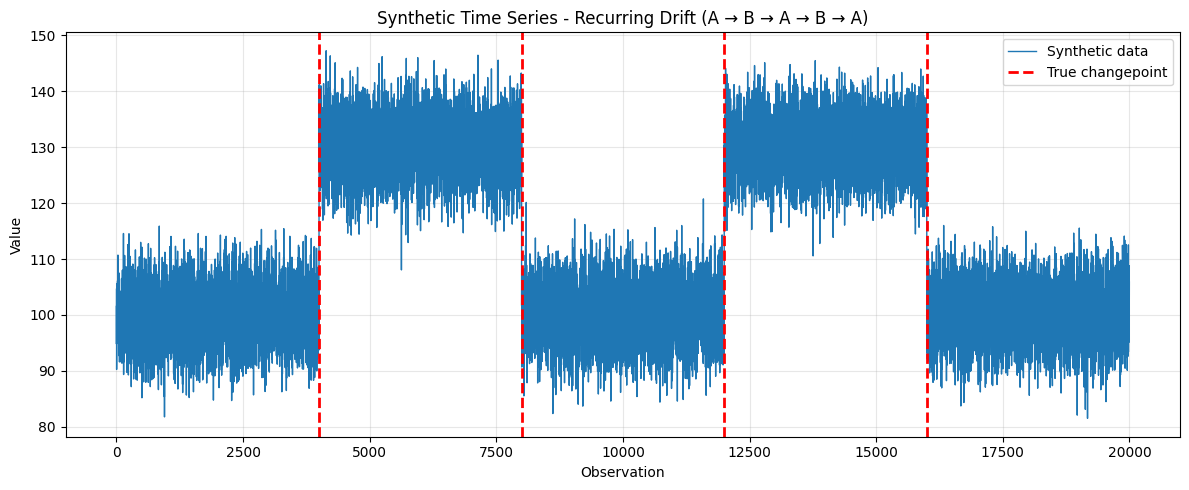

In [9]:
# NUMPY SYNTHETIC BENCHMARK - RECURRING DRIFT
# Plot the synthetic series with known true changepoints

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Synthetic recurring-drift series
plt.plot(
    y_recurring,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_recurring):
    plt.axvline(
        x=cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

plt.title("Synthetic Time Series - Recurring Drift (A → B → A → B → A)")
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

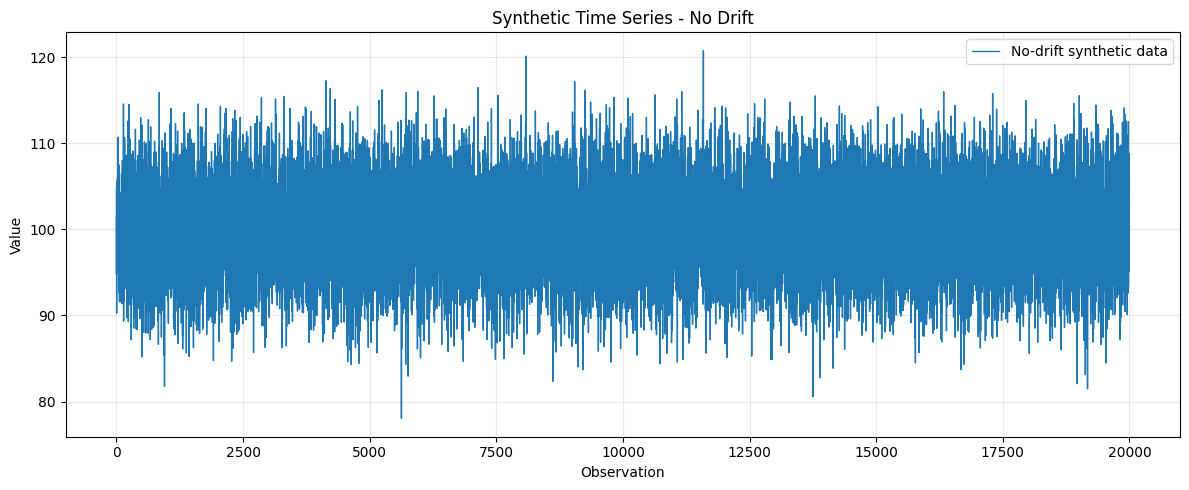

In [10]:
# NUMPY SYNTHETIC BENCHMARK - NO DRIFT
# Stationary control series with no planted changepoints

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_no_drift,
    linewidth=1,
    label="No-drift synthetic data"
)

plt.title("Synthetic Time Series - No Drift")
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
!pip install river

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 62.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 135.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.2 which is incompatible.


In [11]:
from river import drift

print("River imported successfully")

River imported successfully


# ADWIN

In [12]:
from river import drift

adwin = drift.ADWIN()

detected_drifts_no_drift = []

for i, value in enumerate(y_no_drift):
    adwin.update(value)

    if adwin.drift_detected:
        detected_drifts_no_drift.append(i)

print("True changepoints:", cp_no_drift)
print("ADWIN detected:", detected_drifts_no_drift)

True changepoints: []
ADWIN detected: []


In [13]:
from river import drift

adwin = drift.ADWIN()

detected_sudden = []

for i, value in enumerate(y_sudden):
    adwin.update(value)

    if adwin.drift_detected:
        detected_sudden.append(i)

print("True changepoints:", cp_sudden)
print("ADWIN detected:", detected_sudden)

True changepoints: [6666, 13333]
ADWIN detected: [6687, 13343]


In [14]:
delays = [
    detected - true
    for true, detected in zip(cp_sudden, detected_sudden)
]

print("True changepoints:", cp_sudden)
print("ADWIN detections:", detected_sudden)
print("Detection delays:", delays)
print("Average detection delay:", sum(delays) / len(delays))

True changepoints: [6666, 13333]
ADWIN detections: [6687, 13343]
Detection delays: [21, 10]
Average detection delay: 15.5


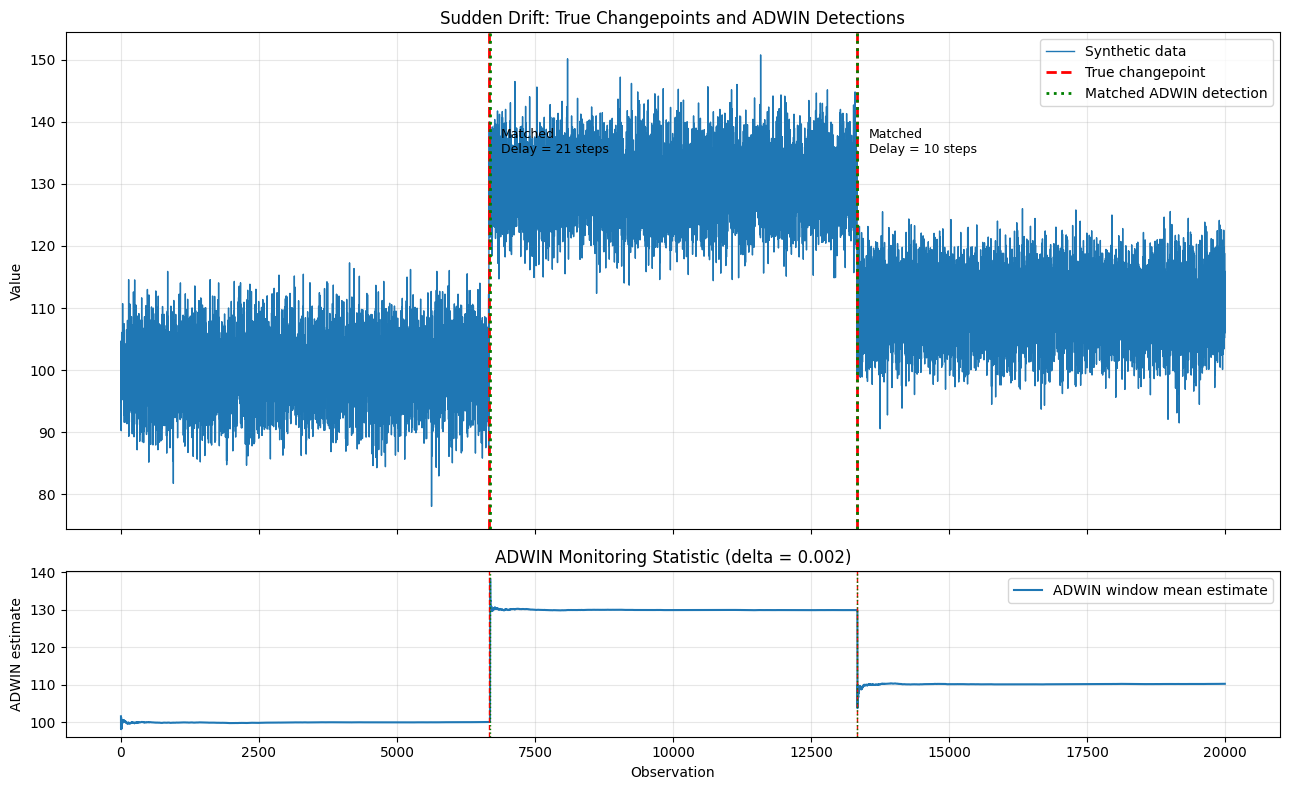

In [16]:
# NUMPY SYNTHETIC BENCHMARK - SUDDEN DRIFT
# ADWIN
# Shows series, true changepoints, matched detections,
# false alarms, detection delay, and ADWIN monitoring statistic

import matplotlib.pyplot as plt
import numpy as np
from river import drift

# Re-run ADWIN so we can save its monitoring statistics
adwin_plot = drift.ADWIN()

adwin_estimation = []
adwin_width = []
adwin_detections_plot = []

for i, value in enumerate(y_sudden):

    adwin_plot.update(value)

    # Save ADWIN statistics after every observation
    adwin_estimation.append(adwin_plot.estimation)
    adwin_width.append(adwin_plot.width)

    if adwin_plot.drift_detected:
        adwin_detections_plot.append(i)


# Match detections to true changepoints
max_delay = 1000

matched_detections = []
detection_delays = []

for true_cp in cp_sudden:

    candidates = [
        d for d in adwin_detections_plot
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_detections
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_detections.append(detected_cp)
        detection_delays.append(detected_cp - true_cp)


# Any unmatched detections are false alarms
false_alarms = [
    d for d in adwin_detections_plot
    if d not in matched_detections
]


# Create two-panel figure
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}
)


# TOP PANEL
# Synthetic series
ax1.plot(
    y_sudden,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_sudden):
    ax1.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )


# Matched ADWIN detections
for i, (detected, delay) in enumerate(
    zip(matched_detections, detection_delays)
):

    ax1.axvline(
        detected,
        color="green",
        linestyle=":",
        linewidth=2,
        label="Matched ADWIN detection" if i == 0 else None
    )

    ax1.annotate(
        f"Matched\nDelay = {delay} steps",
        xy=(detected, ax1.get_ylim()[1] * 0.90),
        xytext=(8, 0),
        textcoords="offset points",
        fontsize=9,
        rotation=0,
        va="top"
    )


# False alarms
for i, false_alarm in enumerate(false_alarms):

    ax1.axvline(
        false_alarm,
        color="purple",
        linestyle=":",
        linewidth=1.5,
        label="False alarm" if i == 0 else None
    )

    ax1.annotate(
        "False alarm",
        xy=(false_alarm, ax1.get_ylim()[1] * 0.75),
        xytext=(8, 0),
        textcoords="offset points",
        fontsize=8,
        rotation=0,
        va="top"
    )


ax1.set_title(
    "Sudden Drift: True Changepoints and ADWIN Detections"
)

ax1.set_ylabel("Value")
ax1.legend()
ax1.grid(alpha=0.3)


# BOTTOM PANEL
# ADWIN estimated mean
ax2.plot(
    adwin_estimation,
    linewidth=1.5,
    label="ADWIN window mean estimate"
)

# True changepoints again for alignment
for cp in cp_sudden:
    ax2.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=1
    )

# ADWIN detections
for cp in adwin_detections_plot:
    ax2.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1
    )

ax2.set_title(
    f"ADWIN Monitoring Statistic (delta = {adwin_plot.delta})"
)

ax2.set_xlabel("Observation")
ax2.set_ylabel("ADWIN estimate")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

In [18]:
adwin_gradual = drift.ADWIN()

detected_gradual = []

for i, value in enumerate(y_gradual):
    adwin_gradual.update(value)

    if adwin_gradual.drift_detected:
        detected_gradual.append(i)

print("Gradual drift starts:", cp_gradual[0])
print("Gradual drift ends:", cp_gradual[1])
print("ADWIN detected:", detected_gradual)

Gradual drift starts: 6666
Gradual drift ends: 13333
ADWIN detected: [7071, 7839, 8447, 9247, 9695, 10335, 11007, 11551, 12287, 13023]


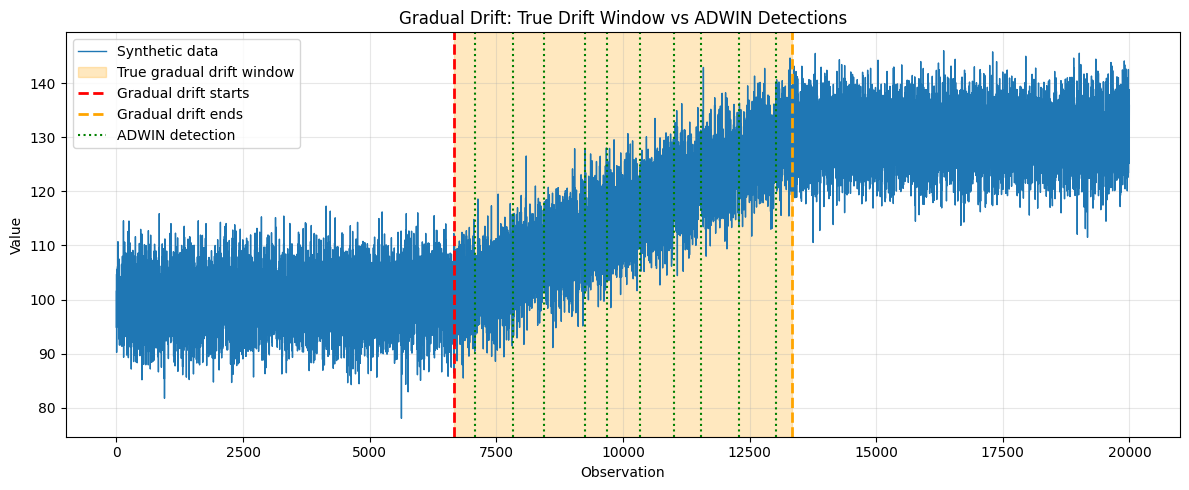

In [19]:
# NUMPY SYNTHETIC BENCHMARK - GRADUAL DRIFT
# Show the true gradual-drift interval as a shaded window

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_gradual,
    linewidth=1,
    label="Synthetic data"
)

# True gradual drift window
plt.axvspan(
    cp_gradual[0],
    cp_gradual[1],
    alpha=0.25,
    color="orange",
    label="True gradual drift window"
)

# Start boundary
plt.axvline(
    cp_gradual[0],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End boundary
plt.axvline(
    cp_gradual[1],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# ADWIN detections
for i, cp in enumerate(detected_gradual):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="ADWIN detection" if i == 0 else None
    )

plt.title(
    "Gradual Drift: True Drift Window vs ADWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
adwin_recurring = drift.ADWIN()

detected_recurring = []

for i, value in enumerate(y_recurring):
    adwin_recurring.update(value)

    if adwin_recurring.drift_detected:
        detected_recurring.append(i)

print("True changepoints:", cp_recurring)
print("ADWIN detected:", detected_recurring)

True changepoints: [4000, 8000, 12000, 16000]
ADWIN detected: [4031, 8031, 12031, 16031]


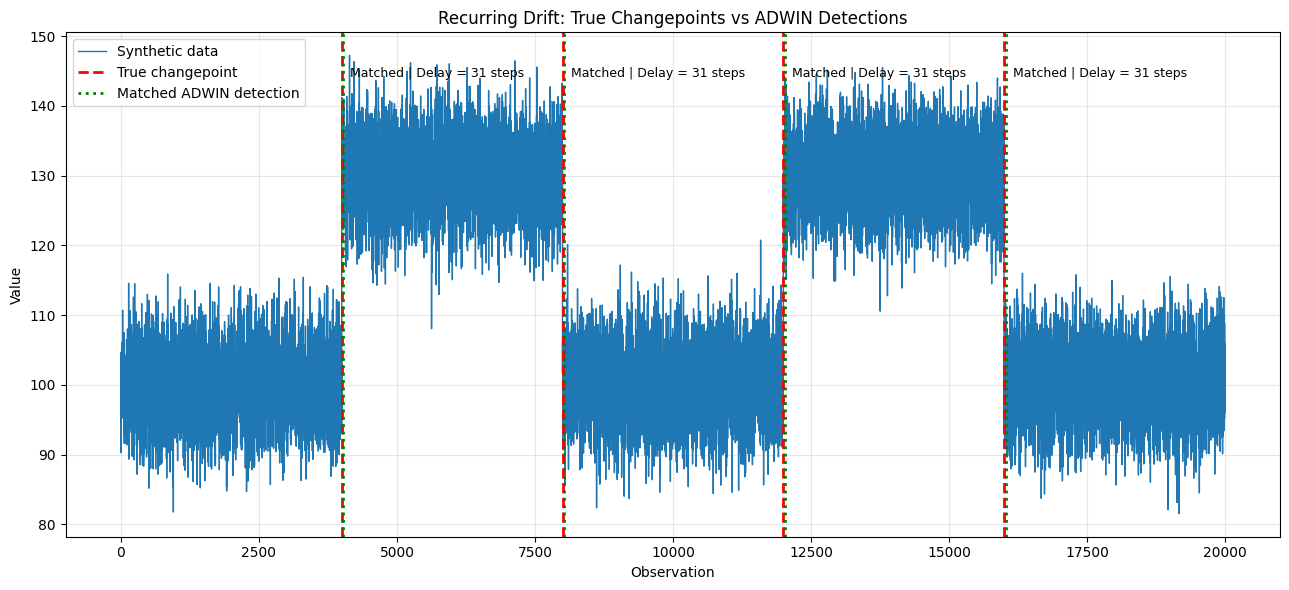

In [21]:
# NUMPY SYNTHETIC BENCHMARK - RECURRING DRIFT
# ADWIN detections with matched/false-alarm labels

import matplotlib.pyplot as plt

# Maximum allowed delay after each true changepoint
max_delay = 1000

# --------------------------------------------------
# Match detections to true changepoints
# --------------------------------------------------

matched_detections = []
detection_delays = []

for true_cp in cp_recurring:

    candidates = [
        d for d in detected_recurring
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_detections
    ]

    if candidates:
        detected = candidates[0]

        matched_detections.append(detected)
        detection_delays.append(detected - true_cp)


# Everything not matched is a false alarm
false_alarms = [
    d for d in detected_recurring
    if d not in matched_detections
]


# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

# Synthetic data
ax.plot(
    y_recurring,
    linewidth=1,
    label="Synthetic data"
)


# True changepoints
for i, cp in enumerate(cp_recurring):

    ax.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )


# Matched ADWIN detections
for i, (detected, delay) in enumerate(
    zip(matched_detections, detection_delays)
):

    ax.axvline(
        detected,
        color="green",
        linestyle=":",
        linewidth=2,
        label="Matched ADWIN detection" if i == 0 else None
    )

    ax.annotate(
        f"Matched | Delay = {delay} steps",
        xy=(detected, ax.get_ylim()[1]),
        xytext=(5, -25),
        textcoords="offset points",
        fontsize=9,
        rotation=0,       # horizontal
        ha="left",
        va="top"
    )


# False alarms
for i, false_alarm in enumerate(false_alarms):

    ax.axvline(
        false_alarm,
        color="purple",
        linestyle=":",
        linewidth=1.5,
        label="False alarm" if i == 0 else None
    )

    ax.annotate(
        "False alarm",
        xy=(false_alarm, ax.get_ylim()[1]),
        xytext=(5, -45),
        textcoords="offset points",
        fontsize=9,
        rotation=0,       # horizontal
        ha="left",
        va="top"
    )


ax.set_title(
    "Recurring Drift: True Changepoints vs ADWIN Detections"
)

ax.set_xlabel("Observation")
ax.set_ylabel("Value")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Calculate detection delays
recurring_delays = [
    detected - true
    for true, detected in zip(cp_recurring, detected_recurring)
]

# Number of missed true drifts
missed_detections = max(
    0,
    len(cp_recurring) - len(detected_recurring)
)

print("True changepoints:", cp_recurring)
print("ADWIN detections:", detected_recurring)
print("Detection delays:", recurring_delays)
print("Average detection delay:", np.mean(recurring_delays))
print("Missed detections:", missed_detections)

True changepoints: [4000, 8000, 12000, 16000]
ADWIN detections: [4031, 8031, 12031, 16031]
Detection delays: [31, 31, 31, 31]
Average detection delay: 31.0
Missed detections: 0


In [23]:
results = pd.DataFrame({
    "Drift Type": ["Sudden", "Recurring", "No Drift"],
    "True Changes": [len(cp_sudden), len(cp_recurring), 0],
    "Detected Changes": [
        len(detected_sudden),
        len(detected_recurring),
        len(detected_drifts_no_drift)
    ],
    "Average Delay": [
        np.mean(delays),
        np.mean(recurring_delays),
        np.nan
    ],
    "Missed": [
        len(cp_sudden) - len(detected_sudden),
        len(cp_recurring) - len(detected_recurring),
        0
    ],
    "False Alarms": [
        0,
        0,
        len(detected_drifts_no_drift)
    ]
})

results

,Drift Type,True Changes,Detected Changes,Average Delay,Missed,False Alarms
0,Sudden,2,2,15.5,0,0
1,Recurring,4,4,31.0,0,0
2,No Drift,0,0,NaN,0,0


In [24]:
gradual_start = cp_gradual[0]
gradual_end = cp_gradual[1]

# ADWIN detections that happened during the gradual transition
inside_gradual = [
    d for d in detected_gradual
    if gradual_start <= d <= gradual_end
]

# Detections outside the true gradual-drift window
outside_gradual = [
    d for d in detected_gradual
    if d < gradual_start or d > gradual_end
]

# Delay from the START of gradual drift to first detection
if len(inside_gradual) > 0:
    first_detection_delay = inside_gradual[0] - gradual_start
else:
    first_detection_delay = np.nan

print("Gradual drift window:", gradual_start, "to", gradual_end)
print("ADWIN detections:", detected_gradual)
print("Detections inside drift window:", inside_gradual)
print("Detections outside drift window:", outside_gradual)
print("First detection delay:", first_detection_delay)

Gradual drift window: 6666 to 13333
ADWIN detections: [7071, 7839, 8447, 9247, 9695, 10335, 11007, 11551, 12287, 13023]
Detections inside drift window: [7071, 7839, 8447, 9247, 9695, 10335, 11007, 11551, 12287, 13023]
Detections outside drift window: []
First detection delay: 405


In [25]:
# Gradual drift summary
gradual_detected = 1 if len(inside_gradual) > 0 else 0
gradual_missed = 0 if gradual_detected == 1 else 1
gradual_false_alarms = len(outside_gradual)

print("Gradual Drift Summary")
print("---------------------")
print("True drift events:", 1)
print("Drift detected:", gradual_detected)
print("First detection delay:", first_detection_delay)
print("Missed detections:", gradual_missed)
print("False alarms:", gradual_false_alarms)
print("Repeated detections inside drift window:", max(0, len(inside_gradual) - 1))

Gradual Drift Summary
---------------------
True drift events: 1
Drift detected: 1
First detection delay: 405
Missed detections: 0
False alarms: 0
Repeated detections inside drift window: 9


In [26]:
import pandas as pd
import numpy as np

final_results = pd.DataFrame({
    "Drift Type": [
        "Sudden",
        "Gradual",
        "Recurring",
        "No Drift"
    ],

    "True Drift Events": [
        len(cp_sudden),
        1,
        len(cp_recurring),
        0
    ],

    "Detected Events": [
        len(detected_sudden),
        gradual_detected,
        len(detected_recurring),
        0
    ],

    "Detection Delay": [
        np.mean(delays),
        first_detection_delay,
        np.mean(recurring_delays),
        np.nan
    ],

    "Missed Detections": [
        len(cp_sudden) - len(detected_sudden),
        gradual_missed,
        len(cp_recurring) - len(detected_recurring),
        0
    ],

    "False Alarms": [
        0,
        gradual_false_alarms,
        0,
        len(detected_drifts_no_drift)
    ],

    "Repeated Detections": [
        0,
        max(0, len(inside_gradual) - 1),
        0,
        0
    ]
})

final_results

,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections
0,Sudden,2,2,15.5,0,0,0
1,Gradual,1,1,405.0,0,0,9
2,Recurring,4,4,31.0,0,0,0
3,No Drift,0,0,NaN,0,0,0


In [27]:
# Number of observations in each synthetic experiment
n_observations = 20000

final_results["False Alarms per 10k"] = (
    final_results["False Alarms"] / n_observations
) * 10000

final_results

,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections,False Alarms per 10k
0,Sudden,2,2,15.5,0,0,0,0.0
1,Gradual,1,1,405.0,0,0,9,0.0
2,Recurring,4,4,31.0,0,0,0,0.0
3,No Drift,0,0,NaN,0,0,0,0.0


In [28]:
final_results.to_csv(
    "adwin_synthetic_benchmark_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


# PageHinkley

In [29]:
from river import drift

ph_no_drift = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_no_drift = []

for i, value in enumerate(y_no_drift):
    ph_no_drift.update(value)

    if ph_no_drift.drift_detected:
        detected_ph_no_drift.append(i)

print("True changepoints:", cp_no_drift)
print("Page-Hinkley detected:", detected_ph_no_drift)
print("Number of false alarms:", len(detected_ph_no_drift))
print(
    "False alarms per 10k:",
    len(detected_ph_no_drift) / len(y_no_drift) * 10000
)

True changepoints: []
Page-Hinkley detected: [1753, 2296, 3909, 4843, 5367, 5897, 6468, 7187, 8143, 9280, 9652, 11023, 11238, 11573, 12782, 13535, 14152, 15358, 16902, 17481, 17842, 18243, 18887, 19908]
Number of false alarms: 24
False alarms per 10k: 11.999999999999998


In [30]:
from river import drift

ph_sudden = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_sudden = []

for i, value in enumerate(y_sudden):
    ph_sudden.update(value)

    if ph_sudden.drift_detected:
        detected_ph_sudden.append(i)

print("True changepoints:", cp_sudden)
print("Page-Hinkley detected:", detected_ph_sudden)
print("Number of detections:", len(detected_ph_sudden))

True changepoints: [6666, 13333]
Page-Hinkley detected: [1753, 2296, 3909, 4843, 5367, 5897, 6468, 6672, 7507, 8336, 9280, 9652, 11023, 11238, 11573, 12782, 13342, 13752, 14104, 14554, 15567, 16939, 17488, 17838, 18245, 18888, 19908]
Number of detections: 27


In [31]:
# Maximum acceptable detection delay
max_delay = 200

matched_ph_sudden = []
delays_ph_sudden = []

# Match each true changepoint with the first Page-Hinkley
# detection occurring within 200 observations after it
for true_cp in cp_sudden:

    candidates = [
        d for d in detected_ph_sudden
        if true_cp <= d <= true_cp + max_delay
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_ph_sudden.append(detected_cp)
        delays_ph_sudden.append(
            detected_cp - true_cp
        )

# Any detection not matched to a true drift is a false alarm
false_alarms_ph_sudden = [
    d for d in detected_ph_sudden
    if d not in matched_ph_sudden
]

# Count missed true drifts
missed_ph_sudden = (
    len(cp_sudden) - len(matched_ph_sudden)
)

print("True changepoints:", cp_sudden)
print("Matched detections:", matched_ph_sudden)
print("Detection delays:", delays_ph_sudden)
print("Average detection delay:", np.mean(delays_ph_sudden))
print("Missed detections:", missed_ph_sudden)
print("False alarms:", len(false_alarms_ph_sudden))

True changepoints: [6666, 13333]
Matched detections: [6672, 13342]
Detection delays: [6, 9]
Average detection delay: 7.5
Missed detections: 0
False alarms: 25


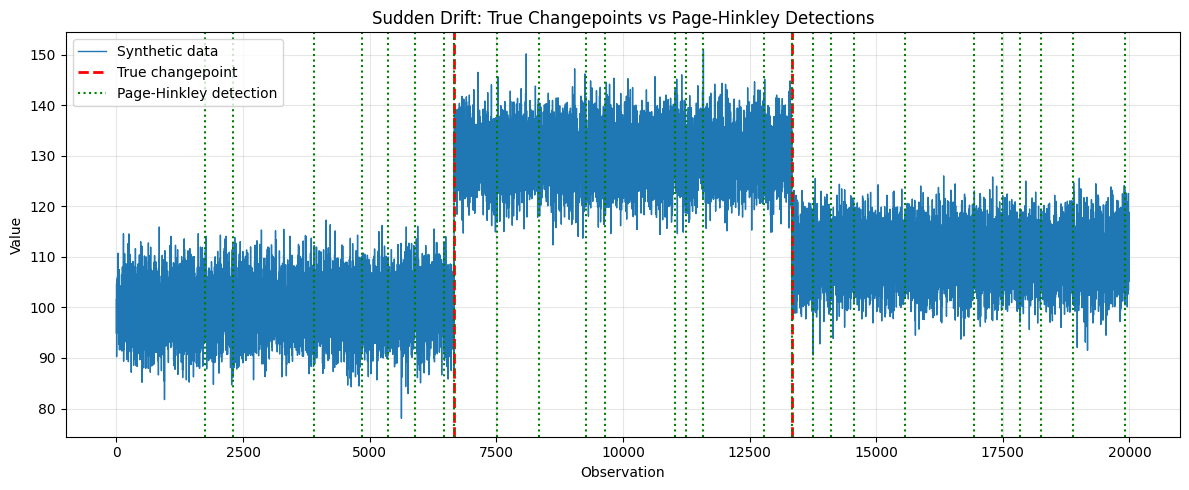

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Synthetic sudden-drift data
plt.plot(
    y_sudden,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

# ALL Page-Hinkley detections
for i, cp in enumerate(detected_ph_sudden):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="Page-Hinkley detection" if i == 0 else None
    )

plt.title(
    "Sudden Drift: True Changepoints vs Page-Hinkley Detections"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
from river import drift

ph_gradual = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_gradual = []

for i, value in enumerate(y_gradual):
    ph_gradual.update(value)

    if ph_gradual.drift_detected:
        detected_ph_gradual.append(i)

print("Gradual drift starts:", cp_gradual[0])
print("Gradual drift ends:", cp_gradual[1])
print("Page-Hinkley detected:", detected_ph_gradual)

Gradual drift starts: 6666
Gradual drift ends: 13333
Page-Hinkley detected: [1753, 2296, 3909, 4843, 5367, 5897, 6468, 6952, 7333, 7641, 7881, 8079, 8445, 8871, 9253, 9509, 9759, 9998, 10331, 10606, 10997, 11530, 11958, 12304, 12592, 13071, 13728, 14100, 14554, 15567, 16939, 17488, 17838, 18245, 18888, 19908]


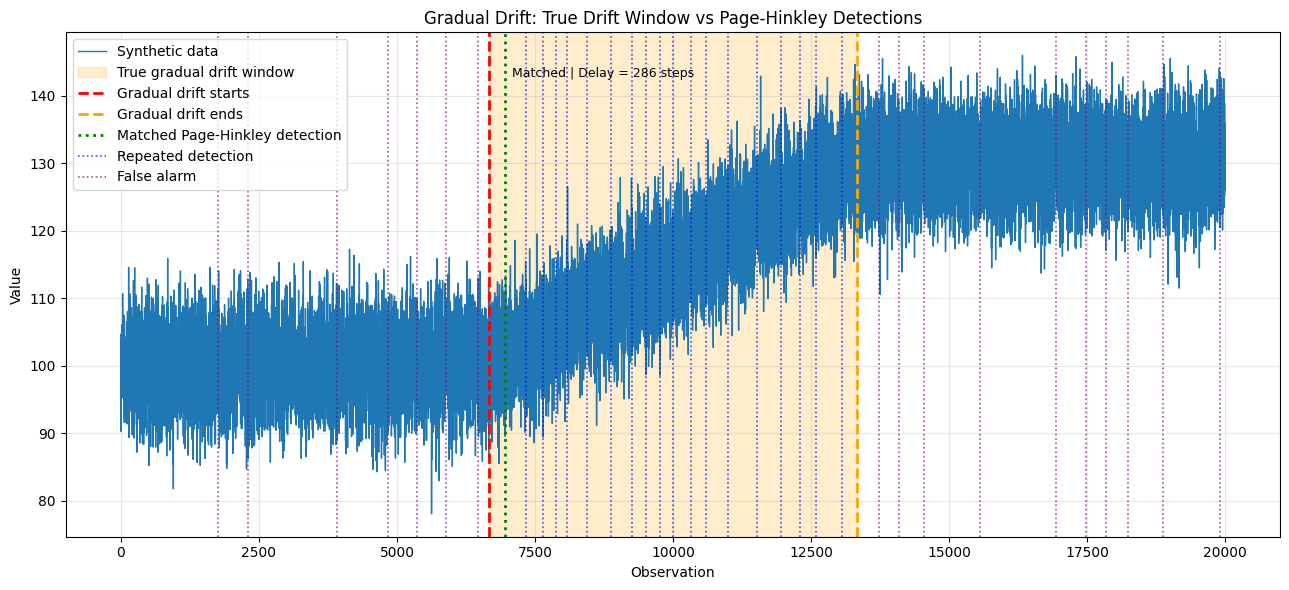

In [37]:
# NUMPY SYNTHETIC BENCHMARK - GRADUAL DRIFT
# Page-Hinkley detections with true drift window,
# matched detection, repeated detections, and false alarms

import matplotlib.pyplot as plt

gradual_start = cp_gradual[0]
gradual_end = cp_gradual[1]

# Detections inside the true gradual-drift window
inside_ph_gradual = [
    d for d in detected_ph_gradual
    if gradual_start <= d <= gradual_end
]

# First detection inside the window = matched detection
matched_ph_gradual = (
    inside_ph_gradual[0]
    if inside_ph_gradual else None
)

# Remaining detections inside the same gradual event = repeated detections
repeated_ph_gradual = (
    inside_ph_gradual[1:]
    if len(inside_ph_gradual) > 1
    else []
)

# Detections outside the true gradual window = false alarms
false_alarms_ph_gradual = [
    d for d in detected_ph_gradual
    if d < gradual_start or d > gradual_end
]

fig, ax = plt.subplots(figsize=(13, 6))

# Synthetic data
ax.plot(
    y_gradual,
    linewidth=1,
    label="Synthetic data"
)

# Shade the full gradual-drift interval
ax.axvspan(
    gradual_start,
    gradual_end,
    color="orange",
    alpha=0.20,
    label="True gradual drift window"
)

# Drift start
ax.axvline(
    gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# Drift end
ax.axvline(
    gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# Matched detection
if matched_ph_gradual is not None:

    delay = matched_ph_gradual - gradual_start

    ax.axvline(
        matched_ph_gradual,
        color="green",
        linestyle=":",
        linewidth=2,
        label="Matched Page-Hinkley detection"
    )

    ax.annotate(
        f"Matched | Delay = {delay} steps",
        xy=(matched_ph_gradual, ax.get_ylim()[1]),
        xytext=(5, -25),
        textcoords="offset points",
        fontsize=9,
        rotation=0,
        ha="left",
        va="top"
    )

# Repeated detections inside the same gradual event
for i, d in enumerate(repeated_ph_gradual):

    ax.axvline(
        d,
        color="blue",
        linestyle=":",
        linewidth=1.2,
        alpha=0.7,
        label="Repeated detection" if i == 0 else None
    )

# False alarms outside the drift window
for i, d in enumerate(false_alarms_ph_gradual):

    ax.axvline(
        d,
        color="purple",
        linestyle=":",
        linewidth=1.2,
        alpha=0.7,
        label="False alarm" if i == 0 else None
    )

ax.set_title(
    "Gradual Drift: True Drift Window vs Page-Hinkley Detections"
)

ax.set_xlabel("Observation")
ax.set_ylabel("Value")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [59]:
gradual_start = cp_gradual[0]
gradual_end = cp_gradual[1]

# Page-Hinkley detections that happened
# during the true gradual transition
inside_ph_gradual = [
    d for d in detected_ph_gradual
    if gradual_start <= d <= gradual_end
]

# Page-Hinkley detections outside
# the true gradual-drift window
outside_ph_gradual = [
    d for d in detected_ph_gradual
    if d < gradual_start or d > gradual_end
]

# Delay from START of gradual drift
# to the first detection inside the window
if len(inside_ph_gradual) > 0:
    first_ph_gradual_delay = (
        inside_ph_gradual[0] - gradual_start
    )
else:
    first_ph_gradual_delay = np.nan

print(
    "Gradual drift window:",
    gradual_start,
    "to",
    gradual_end
)

print(
    "Page-Hinkley detections:",
    detected_ph_gradual
)

print(
    "Detections inside drift window:",
    inside_ph_gradual
)

print(
    "Detections outside drift window:",
    outside_ph_gradual
)

print(
    "First detection delay:",
    first_ph_gradual_delay
)

Gradual drift window: 6666 to 13333
Page-Hinkley detections: [1753, 2296, 3909, 4843, 5367, 5897, 6468, 6952, 7333, 7641, 7881, 8079, 8445, 8871, 9253, 9509, 9759, 9998, 10331, 10606, 10997, 11530, 11958, 12304, 12592, 13071, 13728, 14100, 14554, 15567, 16939, 17488, 17838, 18245, 18888, 19908]
Detections inside drift window: [6952, 7333, 7641, 7881, 8079, 8445, 8871, 9253, 9509, 9759, 9998, 10331, 10606, 10997, 11530, 11958, 12304, 12592, 13071]
Detections outside drift window: [1753, 2296, 3909, 4843, 5367, 5897, 6468, 13728, 14100, 14554, 15567, 16939, 17488, 17838, 18245, 18888, 19908]
First detection delay: 286


In [60]:
# Was the gradual drift detected?
ph_gradual_detected = (
    1 if len(inside_ph_gradual) > 0 else 0
)

# Was the gradual drift missed?
ph_gradual_missed = (
    0 if ph_gradual_detected == 1 else 1
)

# Detections outside the drift window are false alarms
ph_gradual_false_alarms = len(
    outside_ph_gradual
)

# After the first valid detection,
# additional detections inside the same drift window
# are counted as repeated detections
ph_gradual_repeated = max(
    0,
    len(inside_ph_gradual) - 1
)

print("Page-Hinkley Gradual Drift Summary")
print("-----------------------------------")
print("True drift events:", 1)
print("Drift detected:", ph_gradual_detected)
print(
    "First detection delay:",
    first_ph_gradual_delay
)
print(
    "Missed detections:",
    ph_gradual_missed
)
print(
    "False alarms:",
    ph_gradual_false_alarms
)
print(
    "Repeated detections inside drift window:",
    ph_gradual_repeated
)

Page-Hinkley Gradual Drift Summary
-----------------------------------
True drift events: 1
Drift detected: 1
First detection delay: 286
Missed detections: 0
False alarms: 17
Repeated detections inside drift window: 18


In [61]:
from river import drift

ph_recurring = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_recurring = []

for i, value in enumerate(y_recurring):
    ph_recurring.update(value)

    if ph_recurring.drift_detected:
        detected_ph_recurring.append(i)

print("True changepoints:", cp_recurring)
print("Page-Hinkley detected:", detected_ph_recurring)
print("Number of detections:", len(detected_ph_recurring))

True changepoints: [4000, 8000, 12000, 16000]
Page-Hinkley detected: [1753, 2296, 3909, 4009, 4836, 5338, 5904, 6460, 7692, 8006, 8988, 9323, 11032, 11317, 11573, 12004, 12633, 13752, 14104, 14554, 15567, 16003, 16981, 18302, 18885, 19908]
Number of detections: 26


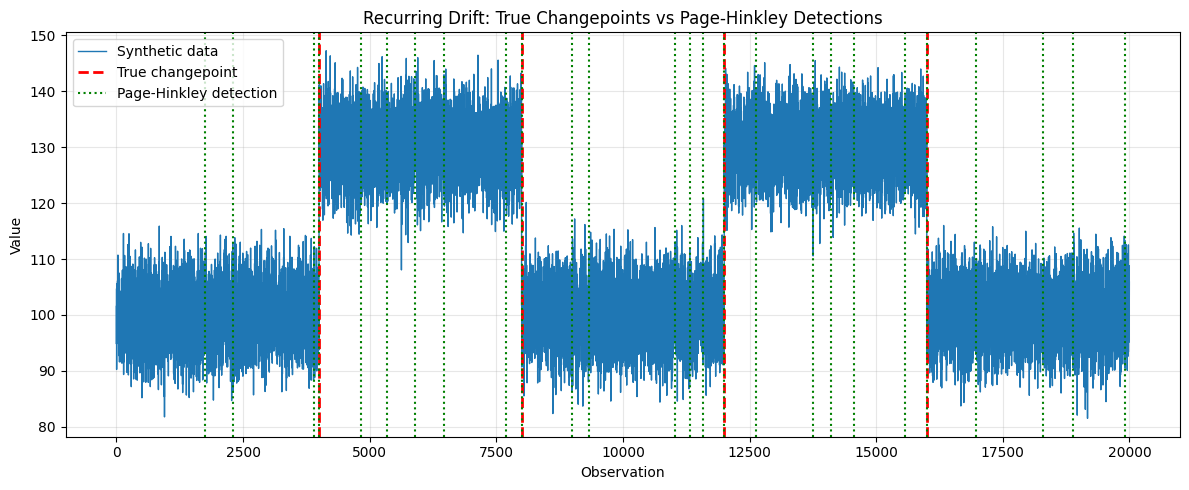

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_recurring,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

# All Page-Hinkley detections
for i, cp in enumerate(detected_ph_recurring):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="Page-Hinkley detection" if i == 0 else None
    )

plt.title(
    "Recurring Drift: True Changepoints vs Page-Hinkley Detections"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
# Maximum acceptable delay after each true changepoint
max_delay = 200

matched_ph_recurring = []
delays_ph_recurring = []

# Match each true changepoint with the first
# Page-Hinkley detection within 200 observations
for true_cp in cp_recurring:

    candidates = [
        d for d in detected_ph_recurring
        if true_cp <= d <= true_cp + max_delay
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_ph_recurring.append(detected_cp)
        delays_ph_recurring.append(
            detected_cp - true_cp
        )

# Detections not matched to a real changepoint
# are counted as false alarms
false_alarms_ph_recurring = [
    d for d in detected_ph_recurring
    if d not in matched_ph_recurring
]

# Number of true changes that were missed
missed_ph_recurring = (
    len(cp_recurring) - len(matched_ph_recurring)
)

# False alarms per 10,000 observations
false_alarms_per_10k_ph_recurring = (
    len(false_alarms_ph_recurring)
    / len(y_recurring)
    * 10000
)

print("True changepoints:", cp_recurring)
print("Matched detections:", matched_ph_recurring)
print("Detection delays:", delays_ph_recurring)
print(
    "Average detection delay:",
    np.mean(delays_ph_recurring)
)
print(
    "Missed detections:",
    missed_ph_recurring
)
print(
    "False alarms:",
    len(false_alarms_ph_recurring)
)
print(
    "False alarms per 10k:",
    false_alarms_per_10k_ph_recurring
)


True changepoints: [4000, 8000, 12000, 16000]
Matched detections: [4009, 8006, 12004, 16003]
Detection delays: [9, 6, 4, 3]
Average detection delay: 5.5
Missed detections: 0
False alarms: 22
False alarms per 10k: 11.0


In [64]:
import pandas as pd
import numpy as np

page_hinkley_results = pd.DataFrame({
    "Drift Type": [
        "Sudden",
        "Gradual",
        "Recurring",
        "No Drift"
    ],

    "True Drift Events": [
        len(cp_sudden),
        1,
        len(cp_recurring),
        0
    ],

    "Detected Events": [
        len(matched_ph_sudden),
        ph_gradual_detected,
        len(matched_ph_recurring),
        0
    ],

    "Detection Delay": [
        np.mean(delays_ph_sudden),
        first_ph_gradual_delay,
        np.mean(delays_ph_recurring),
        np.nan
    ],

    "Missed Detections": [
        missed_ph_sudden,
        ph_gradual_missed,
        missed_ph_recurring,
        0
    ],

    "False Alarms": [
        len(false_alarms_ph_sudden),
        ph_gradual_false_alarms,
        len(false_alarms_ph_recurring),
        len(detected_ph_no_drift)
    ],

    "Repeated Detections": [
        0,
        ph_gradual_repeated,
        0,
        0
    ],

    "False Alarms per 10k": [
        len(false_alarms_ph_sudden) / len(y_sudden) * 10000,
        ph_gradual_false_alarms / len(y_gradual) * 10000,
        len(false_alarms_ph_recurring) / len(y_recurring) * 10000,
        len(detected_ph_no_drift) / len(y_no_drift) * 10000
    ]
})

page_hinkley_results

,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections,False Alarms per 10k
0,Sudden,2,2,7.5,0,25,0,12.5
1,Gradual,1,1,286.0,0,17,18,8.5
2,Recurring,4,4,5.5,0,22,0,11.0
3,No Drift,0,0,NaN,0,24,0,12.0


# KSWIN

In [65]:
from river import drift

# Create KSWIN detector
kswin_no_drift = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_no_drift = []

# Feed observations sequentially
for i, value in enumerate(y_no_drift):
    kswin_no_drift.update(value)

    if kswin_no_drift.drift_detected:
        detected_kswin_no_drift.append(i)

print("True changepoints:", cp_no_drift)
print("KSWIN detected:", detected_kswin_no_drift)
print("Number of false alarms:", len(detected_kswin_no_drift))

print(
    "False alarms per 10k:",
    len(detected_kswin_no_drift)
    / len(y_no_drift)
    * 10000
)

True changepoints: []
KSWIN detected: [783, 1187, 1947, 2504, 4717, 4844, 6463, 6970, 8530, 8984, 9105, 9630, 10480, 11144, 11470, 11628, 13452, 13770, 14554, 14960, 15397, 16759, 18090, 18287, 18659, 19744]
Number of false alarms: 26
False alarms per 10k: 13.0


In [66]:
from river import drift

kswin_sudden = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_sudden = []

for i, value in enumerate(y_sudden):
    kswin_sudden.update(value)

    if kswin_sudden.drift_detected:
        detected_kswin_sudden.append(i)

print("True changepoints:", cp_sudden)
print("KSWIN detected:", detected_kswin_sudden)
print("Number of detections:", len(detected_kswin_sudden))

True changepoints: [6666, 13333]
KSWIN detected: [783, 1187, 1947, 2504, 4717, 4844, 6463, 6677, 6967, 9395, 9631, 9838, 10246, 11502, 13340, 13446, 13771, 14969, 15847, 18102, 19151]
Number of detections: 21


In [67]:
# Maximum acceptable detection delay
max_delay = 200

matched_kswin_sudden = []
delays_kswin_sudden = []

for true_cp in cp_sudden:

    candidates = [
        d for d in detected_kswin_sudden
        if true_cp <= d <= true_cp + max_delay
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_kswin_sudden.append(detected_cp)
        delays_kswin_sudden.append(
            detected_cp - true_cp
        )

# Detections not matched to a real changepoint
false_alarms_kswin_sudden = [
    d for d in detected_kswin_sudden
    if d not in matched_kswin_sudden
]

# Missed true drifts
missed_kswin_sudden = (
    len(cp_sudden) - len(matched_kswin_sudden)
)

print("True changepoints:", cp_sudden)
print("Matched detections:", matched_kswin_sudden)
print("Detection delays:", delays_kswin_sudden)
print(
    "Average detection delay:",
    np.mean(delays_kswin_sudden)
)
print(
    "Missed detections:",
    missed_kswin_sudden
)
print(
    "False alarms:",
    len(false_alarms_kswin_sudden)
)
print(
    "False alarms per 10k:",
    len(false_alarms_kswin_sudden)
    / len(y_sudden)
    * 10000
)

True changepoints: [6666, 13333]
Matched detections: [6677, 13340]
Detection delays: [11, 7]
Average detection delay: 9.0
Missed detections: 0
False alarms: 19
False alarms per 10k: 9.5


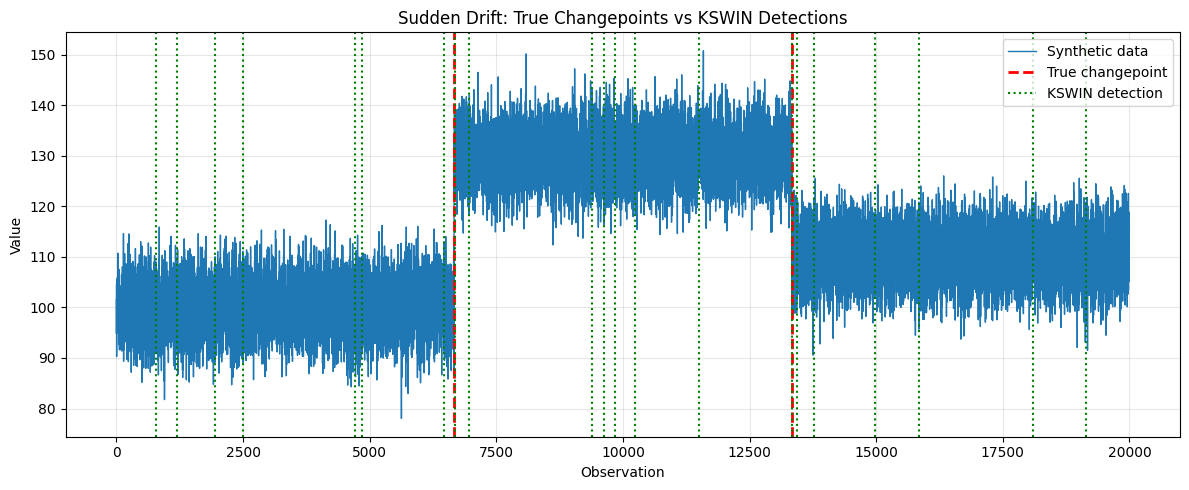

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Synthetic sudden-drift data
plt.plot(
    y_sudden,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

# All KSWIN detections
for i, cp in enumerate(detected_kswin_sudden):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="KSWIN detection" if i == 0 else None
    )

plt.title(
    "Sudden Drift: True Changepoints vs KSWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
from river import drift

kswin_gradual = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_gradual = []

for i, value in enumerate(y_gradual):
    kswin_gradual.update(value)

    if kswin_gradual.drift_detected:
        detected_kswin_gradual.append(i)

print("Gradual drift starts:", cp_gradual[0])
print("Gradual drift ends:", cp_gradual[1])
print("KSWIN detected:", detected_kswin_gradual)
print("Number of detections:", len(detected_kswin_gradual))

Gradual drift starts: 6666
Gradual drift ends: 13333
KSWIN detected: [783, 1187, 1947, 2504, 4717, 4844, 6463, 6970, 8530, 8984, 9390, 10157, 10474, 10752, 11505, 12543, 13452, 13770, 14554, 14960, 15397, 16759, 18090, 18287, 18659, 19744]
Number of detections: 26


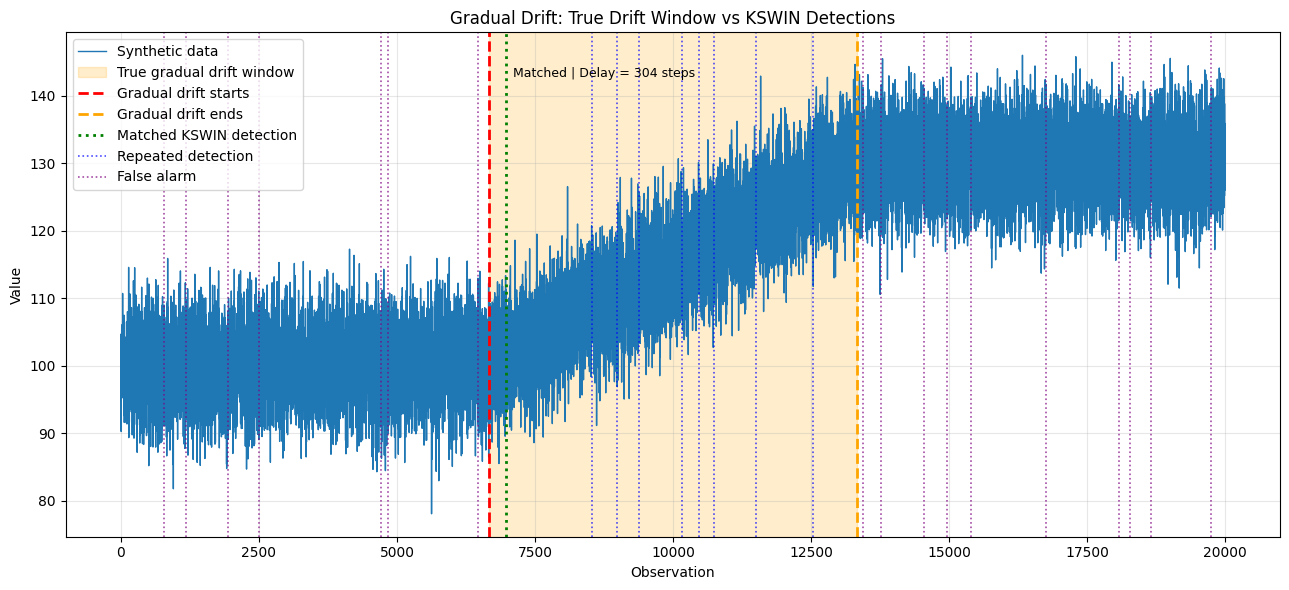

In [39]:
# NUMPY SYNTHETIC BENCHMARK - GRADUAL DRIFT
# KSWIN detections with true drift window,
# matched detection, repeated detections, and false alarms

import matplotlib.pyplot as plt

gradual_start = cp_gradual[0]
gradual_end = cp_gradual[1]

# KSWIN detections inside the true gradual-drift window
inside_kswin_gradual = [
    d for d in detected_kswin_gradual
    if gradual_start <= d <= gradual_end
]

# First detection inside the window = matched detection
matched_kswin_gradual = (
    inside_kswin_gradual[0]
    if inside_kswin_gradual else None
)

# Remaining detections inside the same gradual event = repeated detections
repeated_kswin_gradual = (
    inside_kswin_gradual[1:]
    if len(inside_kswin_gradual) > 1
    else []
)

# Detections outside the true gradual window = false alarms
false_alarms_kswin_gradual = [
    d for d in detected_kswin_gradual
    if d < gradual_start or d > gradual_end
]

fig, ax = plt.subplots(figsize=(13, 6))

# Synthetic data
ax.plot(
    y_gradual,
    linewidth=1,
    label="Synthetic data"
)

# Shade the full true gradual-drift interval
ax.axvspan(
    gradual_start,
    gradual_end,
    color="orange",
    alpha=0.20,
    label="True gradual drift window"
)

# Drift start
ax.axvline(
    gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# Drift end
ax.axvline(
    gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# Matched KSWIN detection
if matched_kswin_gradual is not None:

    delay = matched_kswin_gradual - gradual_start

    ax.axvline(
        matched_kswin_gradual,
        color="green",
        linestyle=":",
        linewidth=2,
        label="Matched KSWIN detection"
    )

    ax.annotate(
        f"Matched | Delay = {delay} steps",
        xy=(matched_kswin_gradual, ax.get_ylim()[1]),
        xytext=(5, -25),
        textcoords="offset points",
        fontsize=9,
        rotation=0,
        ha="left",
        va="top"
    )

# Repeated detections inside the same gradual event
for i, d in enumerate(repeated_kswin_gradual):

    ax.axvline(
        d,
        color="blue",
        linestyle=":",
        linewidth=1.2,
        alpha=0.7,
        label="Repeated detection" if i == 0 else None
    )

# False alarms outside the drift window
for i, d in enumerate(false_alarms_kswin_gradual):

    ax.axvline(
        d,
        color="purple",
        linestyle=":",
        linewidth=1.2,
        alpha=0.7,
        label="False alarm" if i == 0 else None
    )

ax.set_title(
    "Gradual Drift: True Drift Window vs KSWIN Detections"
)

ax.set_xlabel("Observation")
ax.set_ylabel("Value")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [71]:
gradual_start = cp_gradual[0]
gradual_end = cp_gradual[1]

# KSWIN detections inside the gradual drift window
inside_kswin_gradual = [
    d for d in detected_kswin_gradual
    if gradual_start <= d <= gradual_end
]

# KSWIN detections outside the gradual drift window
outside_kswin_gradual = [
    d for d in detected_kswin_gradual
    if d < gradual_start or d > gradual_end
]

# Delay from the start of the gradual drift
# to the first KSWIN detection inside the window
if len(inside_kswin_gradual) > 0:
    first_kswin_gradual_delay = (
        inside_kswin_gradual[0] - gradual_start
    )
else:
    first_kswin_gradual_delay = np.nan

print("Gradual drift window:", gradual_start, "to", gradual_end)
print("KSWIN detections:", detected_kswin_gradual)
print("Detections inside drift window:", inside_kswin_gradual)
print("Detections outside drift window:", outside_kswin_gradual)
print("First detection delay:", first_kswin_gradual_delay)

Gradual drift window: 6666 to 13333
KSWIN detections: [783, 1187, 1947, 2504, 4717, 4844, 6463, 6970, 8530, 8984, 9390, 10157, 10474, 10752, 11505, 12543, 13452, 13770, 14554, 14960, 15397, 16759, 18090, 18287, 18659, 19744]
Detections inside drift window: [6970, 8530, 8984, 9390, 10157, 10474, 10752, 11505, 12543]
Detections outside drift window: [783, 1187, 1947, 2504, 4717, 4844, 6463, 13452, 13770, 14554, 14960, 15397, 16759, 18090, 18287, 18659, 19744]
First detection delay: 304


In [72]:
# Was the gradual drift detected?
kswin_gradual_detected = (
    1 if len(inside_kswin_gradual) > 0 else 0
)

# Was the gradual drift missed?
kswin_gradual_missed = (
    0 if kswin_gradual_detected == 1 else 1
)

# Detections outside the true drift window
# are counted as false alarms
kswin_gradual_false_alarms = len(
    outside_kswin_gradual
)

# First detection = actual detection
# Remaining detections inside the same window = repeated detections
kswin_gradual_repeated = max(
    0,
    len(inside_kswin_gradual) - 1
)

print("KSWIN Gradual Drift Summary")
print("----------------------------")
print("True drift events:", 1)
print("Drift detected:", kswin_gradual_detected)
print(
    "First detection delay:",
    first_kswin_gradual_delay
)
print(
    "Missed detections:",
    kswin_gradual_missed
)
print(
    "False alarms:",
    kswin_gradual_false_alarms
)
print(
    "Repeated detections inside drift window:",
    kswin_gradual_repeated
)

KSWIN Gradual Drift Summary
----------------------------
True drift events: 1
Drift detected: 1
First detection delay: 304
Missed detections: 0
False alarms: 17
Repeated detections inside drift window: 8


In [73]:
from river import drift

kswin_recurring = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_recurring = []

for i, value in enumerate(y_recurring):
    kswin_recurring.update(value)

    if kswin_recurring.drift_detected:
        detected_kswin_recurring.append(i)

print("True changepoints:", cp_recurring)
print("KSWIN detected:", detected_kswin_recurring)
print("Number of detections:", len(detected_kswin_recurring))

True changepoints: [4000, 8000, 12000, 16000]
KSWIN detected: [783, 1187, 1947, 2504, 4013, 4637, 6971, 7134, 7317, 8013, 8527, 9095, 9396, 9631, 9838, 10246, 11502, 12013, 13446, 13771, 14969, 15847, 16011, 16158, 18081, 18663]
Number of detections: 26


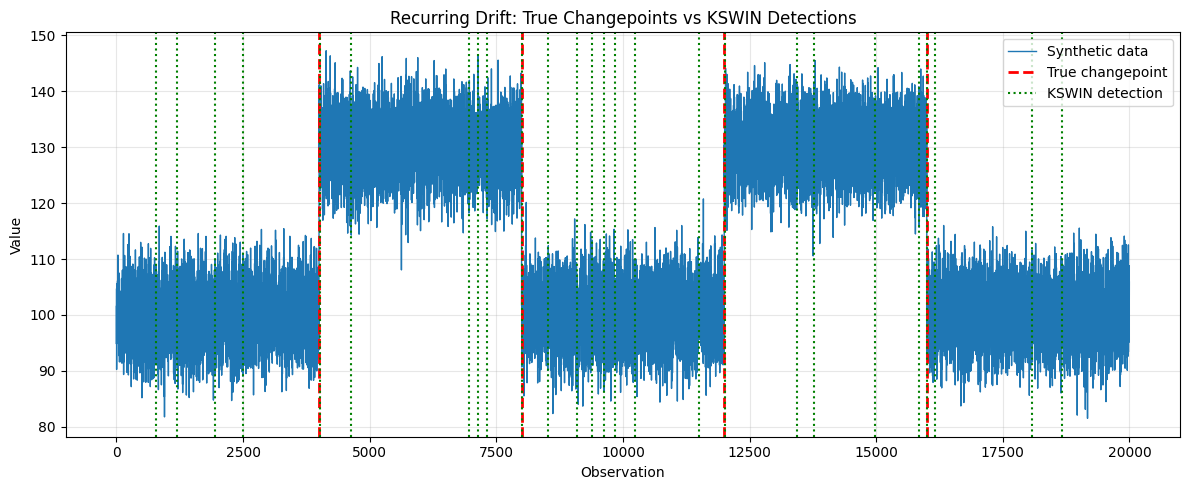

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_recurring,
    linewidth=1,
    label="Synthetic data"
)

# True changepoints
for i, cp in enumerate(cp_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True changepoint" if i == 0 else None
    )

# All KSWIN detections
for i, cp in enumerate(detected_kswin_recurring):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="KSWIN detection" if i == 0 else None
    )

plt.title(
    "Recurring Drift: True Changepoints vs KSWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [75]:
# Maximum acceptable detection delay
max_delay = 200

matched_kswin_recurring = []
delays_kswin_recurring = []

# Match each true changepoint with the first
# KSWIN detection within 200 observations
for true_cp in cp_recurring:

    candidates = [
        d for d in detected_kswin_recurring
        if true_cp <= d <= true_cp + max_delay
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_kswin_recurring.append(detected_cp)

        delays_kswin_recurring.append(
            detected_cp - true_cp
        )

# Any detection not matched to a true changepoint
# is counted as a false alarm
false_alarms_kswin_recurring = [
    d for d in detected_kswin_recurring
    if d not in matched_kswin_recurring
]

# Number of true drifts that were missed
missed_kswin_recurring = (
    len(cp_recurring) - len(matched_kswin_recurring)
)

# False alarms per 10,000 observations
false_alarms_per_10k_kswin_recurring = (
    len(false_alarms_kswin_recurring)
    / len(y_recurring)
    * 10000
)

print("True changepoints:", cp_recurring)
print("Matched detections:", matched_kswin_recurring)
print("Detection delays:", delays_kswin_recurring)

print(
    "Average detection delay:",
    np.mean(delays_kswin_recurring)
)

print(
    "Missed detections:",
    missed_kswin_recurring
)

print(
    "False alarms:",
    len(false_alarms_kswin_recurring)
)

print(
    "False alarms per 10k:",
    false_alarms_per_10k_kswin_recurring
)

True changepoints: [4000, 8000, 12000, 16000]
Matched detections: [4013, 8013, 12013, 16011]
Detection delays: [13, 13, 13, 11]
Average detection delay: 12.5
Missed detections: 0
False alarms: 22
False alarms per 10k: 11.0


In [76]:
import pandas as pd
import numpy as np

kswin_results = pd.DataFrame({
    "Drift Type": [
        "Sudden",
        "Gradual",
        "Recurring",
        "No Drift"
    ],

    "True Drift Events": [
        len(cp_sudden),
        1,
        len(cp_recurring),
        0
    ],

    "Detected Events": [
        len(matched_kswin_sudden),
        kswin_gradual_detected,
        len(matched_kswin_recurring),
        0
    ],

    "Detection Delay": [
        np.mean(delays_kswin_sudden),
        first_kswin_gradual_delay,
        np.mean(delays_kswin_recurring),
        np.nan
    ],

    "Missed Detections": [
        missed_kswin_sudden,
        kswin_gradual_missed,
        missed_kswin_recurring,
        0
    ],

    "False Alarms": [
        len(false_alarms_kswin_sudden),
        kswin_gradual_false_alarms,
        len(false_alarms_kswin_recurring),
        len(detected_kswin_no_drift)
    ],

    "Repeated Detections": [
        0,
        kswin_gradual_repeated,
        0,
        0
    ],

    "False Alarms per 10k": [
        len(false_alarms_kswin_sudden)
        / len(y_sudden) * 10000,

        kswin_gradual_false_alarms
        / len(y_gradual) * 10000,

        len(false_alarms_kswin_recurring)
        / len(y_recurring) * 10000,

        len(detected_kswin_no_drift)
        / len(y_no_drift) * 10000
    ]
})

kswin_results

,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections,False Alarms per 10k
0,Sudden,2,2,9.0,0,19,0,9.5
1,Gradual,1,1,304.0,0,17,8,8.5
2,Recurring,4,4,12.5,0,22,0,11.0
3,No Drift,0,0,NaN,0,26,0,13.0


In [77]:
# Add detector name to each results table
adwin_comparison = final_results.copy()
adwin_comparison["Detector"] = "ADWIN"

ph_comparison = page_hinkley_results.copy()
ph_comparison["Detector"] = "Page-Hinkley"

kswin_comparison = kswin_results.copy()
kswin_comparison["Detector"] = "KSWIN"

# Combine all three
detector_comparison = pd.concat(
    [
        adwin_comparison,
        ph_comparison,
        kswin_comparison
    ],
    ignore_index=True
)

# Put Detector first
cols = [
    "Detector",
    "Drift Type",
    "True Drift Events",
    "Detected Events",
    "Detection Delay",
    "Missed Detections",
    "False Alarms",
    "Repeated Detections"
]

# Include FA/10k if available in all tables
if "False Alarms per 10k" in detector_comparison.columns:
    cols.append("False Alarms per 10k")

detector_comparison = detector_comparison[cols]

detector_comparison

,Detector,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections,False Alarms per 10k
0,ADWIN,Sudden,2,2,15.5,0,0,0,0.0
1,ADWIN,Gradual,1,1,405.0,0,0,9,0.0
2,ADWIN,Recurring,4,4,31.0,0,0,0,0.0
3,ADWIN,No Drift,0,0,NaN,0,0,0,0.0
4,Page-Hinkley,Sudden,2,2,7.5,0,25,0,12.5
5,Page-Hinkley,Gradual,1,1,286.0,0,17,18,8.5
6,Page-Hinkley,Recurring,4,4,5.5,0,22,0,11.0
7,Page-Hinkley,No Drift,0,0,NaN,0,24,0,12.0
8,KSWIN,Sudden,2,2,9.0,0,19,0,9.5
9,KSWIN,Gradual,1,1,304.0,0,17,8,8.5


## Analysis of NumPy Synthetic Drift Detection Benchmark

The NumPy synthetic benchmark was designed to compare the behaviour of three concept drift detectors
- **ADWIN**,
- **Page-Hinkley**,
- **KSWIN**

under controlled conditions where the true drift locations are known. Four scenarios were evaluated: **sudden drift, gradual drift, recurring drift, and no drift**. Each synthetic stream contained 20,000 observations and was processed sequentially so that each detector received observations in time order.

### ADWIN

ADWIN produced the most stable results across the synthetic benchmark. For **sudden drift**, both true changepoints were detected with an average delay of **15.5 observations**, with no missed detections and no false alarms.

For **recurring drift**, all four true changes were detected with an average delay of **31 observations**, again without any false alarms or missed detections.

For **gradual drift**, ADWIN detected the changing distribution **405 observations after the beginning of the drift window**. Nine additional detections occurred inside the same gradual transition. These were treated as repeated detections rather than separate drift events because they occurred while the underlying distribution was continuously changing.

Most importantly, ADWIN produced **zero detections on the no-drift stream**. This indicates that, for this synthetic benchmark, ADWIN was highly resistant to random fluctuations in the data.

### Page-Hinkley

Page-Hinkley reacted considerably faster than ADWIN but produced substantially more false alarms.

For **sudden drift**, Page-Hinkley detected both true changes with an average delay of only **7.5 observations**, compared with 15.5 for ADWIN. However, it also produced **25 false alarms**, equivalent to **12.5 false alarms per 10,000 observations**.

For **gradual drift**, Page-Hinkley detected the drift after **286 observations**, making it the fastest of the three detectors in this scenario. It also generated **18 repeated detections inside the gradual drift window** and **17 detections outside the window**, which were counted as false alarms.

Page-Hinkley performed particularly well in terms of detection speed for **recurring drift**, detecting all four changes with an average delay of only **5.5 observations**. However, this was accompanied by **22 false alarms**.

The no-drift experiment confirmed Page-Hinkley's sensitivity. Although no true drift existed, Page-Hinkley generated **24 false alarms**, or **12 false alarms per 10,000 observations**.

### KSWIN

KSWIN showed behaviour similar to Page-Hinkley, providing relatively fast detection but also producing a considerable number of false alarms.

For **sudden drift**, KSWIN detected both true changes with an average delay of **9 observations**, which was faster than ADWIN but slightly slower than Page-Hinkley. It generated **19 false alarms**, corresponding to **9.5 false alarms per 10,000 observations**.

For **gradual drift**, KSWIN first detected the changing distribution **304 observations after the beginning of the drift window**. It generated **8 repeated detections inside the drift window** and **17 false alarms outside the drift window**.

For **recurring drift**, all four true changepoints were detected with an average delay of **12.5 observations** and no missed detections. However, KSWIN also generated **22 false alarms**.

On the **no-drift stream**, KSWIN generated **26 false alarms**, equivalent to **13 false alarms per 10,000 observations**, which was the highest no-drift false-alarm rate among the three detectors.

### Overall Comparison

The benchmark demonstrates a clear trade-off between **detection speed and false-alarm control**.

| Detector | Sudden Delay | Gradual Delay | Recurring Delay | No-Drift False Alarms |
|---|---:|---:|---:|---:|
| ADWIN | 15.5 | 405 | 31.0 | 0 |
| Page-Hinkley | 7.5 | 286 | 5.5 | 24 |
| KSWIN | 9.0 | 304 | 12.5 | 26 |

**Page-Hinkley was the fastest detector overall**, achieving the lowest detection delay for sudden, gradual, and recurring drift. KSWIN also detected changes faster than ADWIN in all three drift scenarios. However, both Page-Hinkley and KSWIN achieved this increased sensitivity at the cost of frequent false alarms.

In contrast, **ADWIN was slower but substantially more stable**. It detected every true drift event in the sudden and recurring experiments and detected the gradual drift without generating any false alarms outside the defined drift window. Most significantly, ADWIN produced zero alarms when applied to the no-drift control stream.

Therefore, based on this initial NumPy synthetic benchmark, **ADWIN provides the strongest false-alarm control, while Page-Hinkley provides the fastest detection**. KSWIN represents an intermediate result in terms of detection speed but still exhibits a relatively high false-alarm rate.

These results should not be interpreted as demonstrating that one detector is universally superior. Detector performance can depend on its parameter configuration and experimental conditions, including the type and characteristics of the drift and the dataset being monitored (Gonçalves et al., 2014; Barros & Santos, 2018). The current experiment should therefore be treated as a controlled baseline benchmark. Because changes in predictive performance can provide evidence of concept drift (Gama et al., 2014), the next stage will evaluate the detectors in a more realistic regression setting by **monitoring forecast prediction errors**, before applying the drift-detection framework to the real electricity-demand stream.



<br>

**References:**

Barros, R. S. M., & Santos, S. G. T. C. (2018). A large-scale comparison of concept drift detectors. Information Sciences, 451–452, 348–370. https://doi.org/10.1016/j.ins.2018.04.014.
<br>


Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M., & Bouchachia, A. (2014). A survey on concept drift adaptation. ACM Computing Surveys, 46(4), Article 44, 1–37. https://doi.org/10.1145/2523813.
<br>


Gonçalves, P. M., Jr., de Carvalho Santos, S. G. T., Barros, R. S. M., & Vieira, D. C. L. (2014). A comparative study on concept drift detectors. Expert Systems with Applications, 41(18), 8144–8156. https://doi.org/10.1016/j.eswa.2014.07.019.



---



# FriedmanDrift Dataset using River

## Why FriedmanDrift Was Selected

`FriedmanDrift` was selected as the main River benchmark because it closely matches the prediction task and drift-detection methodology used in this project. Unlike many common concept-drift benchmarks that are designed for classification, `FriedmanDrift` is a **regression stream**, where the target \(y\) is a continuous numerical value. This allows drift to be monitored through changes in the regression model's prediction error, which is consistent with the later electricity-demand forecasting stage of this project.

Another important advantage is that `FriedmanDrift` introduces concept drift by changing the **relationship between the input features \(X\) and the target \(y\)**. Therefore, drift does not necessarily appear as an obvious change in the raw target values. Instead, a model trained on the original \(X → y\) relationship can become less accurate when that relationship changes, causing the model's prediction-error distribution to change.

### Connection to the Real AEMO Forecasting Stage

This \(X → y\) concept is relevant to the later AEMO stage. The primary real-data task is to forecast half-hourly `TOTALDEMAND` for SA1 and NSW1. The AEMO data provides a chronological demand series, from which useful forecasting features can later be created.

For example, the timestamp can be transformed into **time-based features** such as:

- hour of day,
- day of week,
- month,
- weekday/weekend indicator.

These are called **engineered features** because they are created from information already available in the real time-series data rather than being separate measurements.


The later regression problem can therefore be represented as:


Time-derived features X → Gradient-Boosted Regression Model → TOTALDEMAND y


For example, the model may learn from historical data that a particular combination of time-based features is normally associated with a particular level of electricity demand:

X= [Hour: 18:00, Day: Monday, Month: January, Day type: Weekday] → y= TOTALDEMAND = 1500 MW


The important point is not the individual feature values themselves, but the **relationship the regression model learns between those features and electricity demand**.


If electricity-consumption behaviour changes over time, the historical relationship may no longer hold. For example, the project brief identifies the gradual deepening of the midday demand trough associated with rooftop solar in South Australia as an example of gradual drift.

Consequently, a gradient-boosted model trained on historical behaviour may begin producing larger prediction errors because the relationship it originally learned no longer represents current demand behaviour.

The connection between the synthetic benchmark and the later real-data stage can therefore be summarized as:

**FriedmanDrift:** synthetic X → regression → continuous y → error → detector

**AEMO:** time-derived X → gradient-boosted regression → TOTALDEMAND y → error → detector


Therefore, `FriedmanDrift` is **not intended to reproduce the exact features of the AEMO dataset**. Instead, it provides a controlled environment for validating the same feature-to-target regression and prediction-error-based drift-detection methodology that will later be applied to the real AEMO forecasting problem.

River also provides several predefined drift behaviours through `FriedmanDrift`. In this benchmark, **LEA (Local Expanding Abrupt)** was used to study abrupt changes, **GSG (Global Slow Gradual)** to study a gradual transition, and **GRA (Global Recurring Abrupt)** to study recurring concept changes. These scenarios allow ADWIN, Page-Hinkley, and KSWIN to be compared under different forms of concept drift while keeping the underlying regression problem consistent.

The synthetic nature of `FriedmanDrift` is also important for evaluation because the drift locations or transition intervals are known. Detector alarms can therefore be compared with the ground truth to calculate **detection delay, missed detections, false alarms, repeated detections, and false alarms per 10,000 observations**.

For these reasons, `FriedmanDrift` provides an intermediate validation stage between the fully controlled NumPy experiments and the later application to real AEMO data. It tests whether the complete pipeline — **features → regression model → prediction error → drift detection** works under known drift conditions before the same principle is applied to naturally changing electricity-demand data.

**Reference:**

River `FriedmanDrift` documentation:  
https://riverml.xyz/dev/api/datasets/synth/FriedmanDrift/

# Lea SUDDEN DRIFT

In [106]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Create FriedmanDrift sudden/abrupt drift generator
# Dataset size target: 100,000 observations
# True drift positions: 25,000, 50,000, 75,000

from river import datasets

river_sudden = datasets.synth.FriedmanDrift(
    drift_type="lea", # Local Expanding Abrupt drift.
    position=(25000, 50000, 75000),
    seed=42
)

print(river_sudden)

Synthetic data generator

    Name  FriedmanDrift
    Task  Regression   
 Samples  ∞            
Features  10           
  Sparse  False        

Configuration
-------------
       drift_type  lea                  
         position  (25000, 50000, 75000)
transition_window  10000                
             seed  42                   


In [107]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Generate 100,000 observations from the FriedmanDrift stream

X_river_sudden = []
y_river_sudden = []

for x, y in river_sudden.take(100000):
    X_river_sudden.append(x)
    y_river_sudden.append(y)

# Store the known true changepoints
cp_river_sudden = [25000, 50000, 75000]

print("Number of observations:", len(y_river_sudden))
print("Number of features:", len(X_river_sudden[0]))
print("True changepoints:", cp_river_sudden)

Number of observations: 100000
Number of features: 10
True changepoints: [25000, 50000, 75000]


In [108]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Train the regression model on pre-drift observations
# Training range: observations 0 to 19,999

from river import linear_model
from river import preprocessing

model_sudden = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression()
)

train_size = 20000

for i in range(train_size):
    model_sudden.learn_one(
        X_river_sudden[i],
        y_river_sudden[i]
    )

print("Model trained successfully")
print("Training observations:", train_size)
print("First true drift:", cp_river_sudden[0])

Model trained successfully
Training observations: 20000
First true drift: 25000


### Why 20,000 Observations Are Used for Training

The model is trained on the first **20,000 observations** because the first known drift occurs at observation **25,000**. Training must contain only **pre-drift data** so the model learns the original concept. Observations **20,000–25,000** provide a stable pre-drift evaluation period, allowing us to measure false alarms before the first real concept change occurs.

In [109]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Generate prediction errors using the frozen pre-drift model
# Evaluation range: observations 20,000 to 99,999

import numpy as np

actual_sudden = []
predictions_sudden = []
errors_river_sudden = []

for i in range(train_size, len(y_river_sudden)):

    x = X_river_sudden[i]
    y_true = y_river_sudden[i]

    # Predict without updating the model
    y_pred = model_sudden.predict_one(x)

    # Absolute prediction error
    error = abs(y_true - y_pred)

    actual_sudden.append(y_true)
    predictions_sudden.append(y_pred)
    errors_river_sudden.append(error)

actual_sudden = np.array(actual_sudden)
predictions_sudden = np.array(predictions_sudden)
errors_river_sudden = np.array(errors_river_sudden)

print("Number of predictions:", len(predictions_sudden))
print("First 5 actual values:", actual_sudden[:5])
print("First 5 predictions:", predictions_sudden[:5])
print("First 5 errors:", errors_river_sudden[:5])

Number of predictions: 80000
First 5 actual values: [11.03818182 17.3227348   4.72988675  7.62561812 10.4335413 ]
First 5 predictions: [13.06330474 15.51847023  5.22177357 10.14005584 15.24081403]
First 5 errors: [2.02512292 1.80426457 0.49188682 2.51443772 4.80727272]


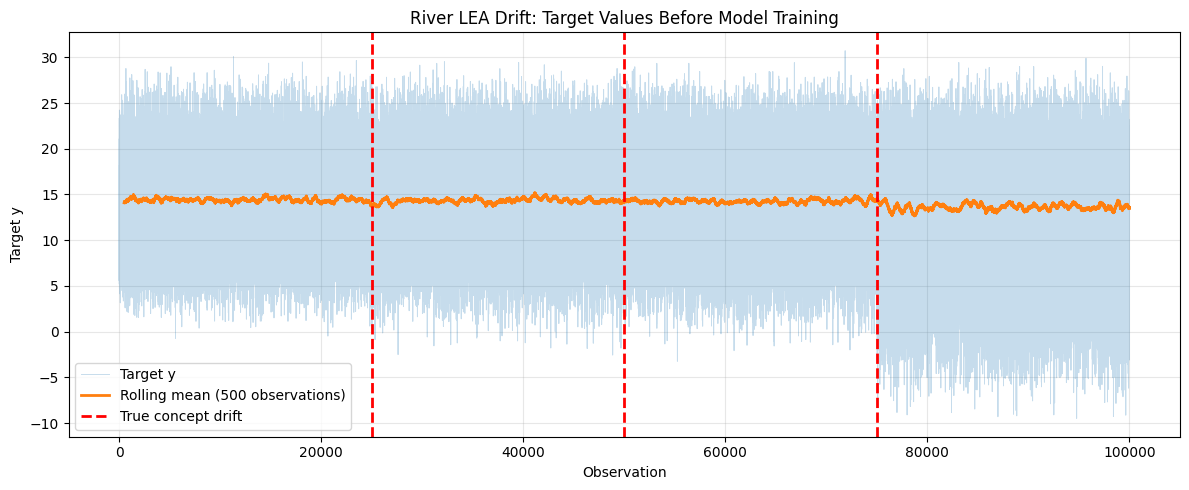

In [110]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Plot the raw target before model training
# This checks whether the concept drift is directly visible in y

import matplotlib.pyplot as plt
import pandas as pd

# Convert the River target values to a pandas Series
y_river_sudden_series = pd.Series(y_river_sudden)

# Rolling mean to make changes in the target distribution easier to see
rolling_y_sudden = y_river_sudden_series.rolling(
    window=500
).mean()

plt.figure(figsize=(12, 5))

# Raw target values
plt.plot(
    y_river_sudden_series,
    alpha=0.25,
    linewidth=0.7,
    label="Target y"
)

# Rolling mean of the target
plt.plot(
    rolling_y_sudden,
    linewidth=2,
    label="Rolling mean (500 observations)"
)

# True River concept drift positions
for i, cp in enumerate(cp_river_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True concept drift" if i == 0 else None
    )

plt.title("River LEA Drift: Target Values Before Model Training")
plt.xlabel("Observation")
plt.ylabel("Target y")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### River LEA Target Behaviour Before Training

The raw target values show that the first two concept changes at **25,000** and **50,000** are not strongly visible from `y` alone. After the third drift at **75,000**, the target distribution becomes more visibly affected and lower values occur more frequently. This illustrates that concept drift represents a change in the underlying **relationship between the features (`X`) and target (`y`)**, although sufficiently strong changes in that relationship can also become visible in the target distribution itself.

In [111]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Apply ADWIN to the frozen model prediction-error stream

from river import drift

adwin_river_sudden = drift.ADWIN()

detected_adwin_river_sudden = []

for i, error in enumerate(errors_river_sudden):
    adwin_river_sudden.update(error)

    if adwin_river_sudden.drift_detected:
        # Convert error-stream index back to original River observation
        original_position = i + train_size
        detected_adwin_river_sudden.append(original_position)

print("True changepoints:", cp_river_sudden)
print("ADWIN detected:", detected_adwin_river_sudden)
print("Number of detections:", len(detected_adwin_river_sudden))

True changepoints: [25000, 50000, 75000]
ADWIN detected: [35423, 53375, 75487]
Number of detections: 3


In [112]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Evaluate ADWIN detections against the true changepoints
# Calculate detection delay, missed detections, and false alarms

import numpy as np

max_delay = 15000

matched_adwin_river_sudden = []
delays_adwin_river_sudden = []

# Match each true drift with the first ADWIN detection after it
for true_cp in cp_river_sudden:

    candidates = [
        d for d in detected_adwin_river_sudden
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_adwin_river_sudden
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_adwin_river_sudden.append(detected_cp)
        delays_adwin_river_sudden.append(
            detected_cp - true_cp
        )

# Any detection that was not matched to a true drift is a false alarm
false_alarms_adwin_river_sudden = [
    d for d in detected_adwin_river_sudden
    if d not in matched_adwin_river_sudden
]

# Any true drift without a matched detection is missed
missed_adwin_river_sudden = (
    len(cp_river_sudden)
    - len(matched_adwin_river_sudden)
)

print("True changepoints:", cp_river_sudden)
print("Matched detections:", matched_adwin_river_sudden)
print("Detection delays:", delays_adwin_river_sudden)

print(
    "Average detection delay:",
    np.mean(delays_adwin_river_sudden)
)

print(
    "Missed detections:",
    missed_adwin_river_sudden
)

print(
    "False alarms:",
    len(false_alarms_adwin_river_sudden)
)

True changepoints: [25000, 50000, 75000]
Matched detections: [35423, 53375, 75487]
Detection delays: [10423, 3375, 487]
Average detection delay: 4761.666666666667
Missed detections: 0
False alarms: 0


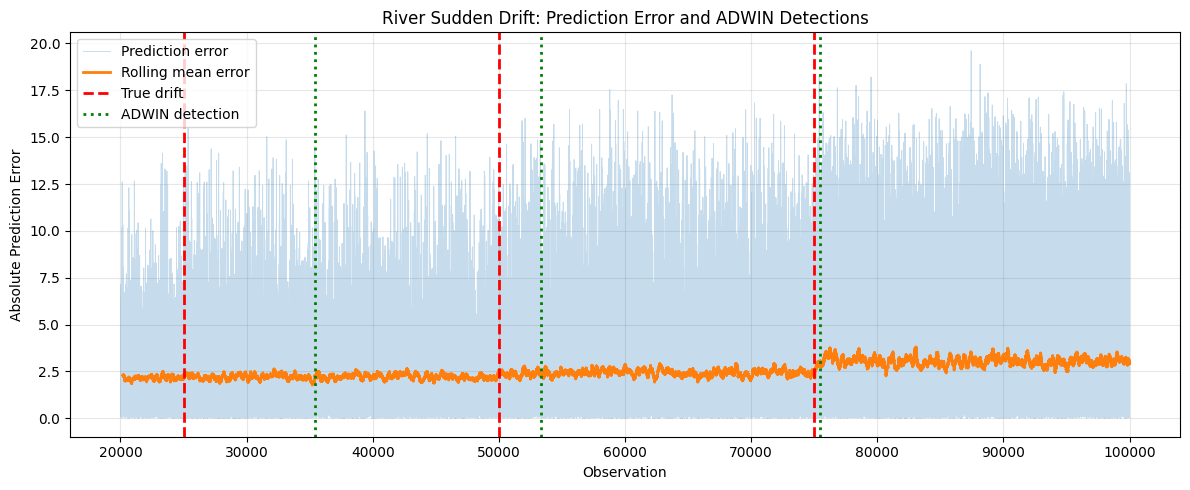

In [113]:
# RIVER BENCHMARK - SUDDEN DRIFT
# Plot raw prediction errors, rolling mean error, true drift points, and ADWIN detections

import matplotlib.pyplot as plt
import pandas as pd

# Put errors into a Series indexed by original observation number
error_series_sudden = pd.Series(
    errors_river_sudden,
    index=range(train_size, len(y_river_sudden))
)

# Smooth the errors to make the underlying pattern easier to see
rolling_error_sudden = error_series_sudden.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_sudden.index,
    error_series_sudden.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean error
plt.plot(
    rolling_error_sudden.index,
    rolling_error_sudden.values,
    linewidth=2,
    label="Rolling mean error"
)

# True River drift positions
for i, cp in enumerate(cp_river_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# ADWIN detections
for i, cp in enumerate(detected_adwin_river_sudden):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=2,
        label="ADWIN detection" if i == 0 else None
    )

plt.title("River Sudden Drift: Prediction Error and ADWIN Detections")
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The LEA concept changes progressively affect the frozen model's predictive performance. Early changes produce relatively small shifts in prediction error, whereas later changes produce a clearer deterioration. Consequently, ADWIN requires substantially more observations to detect the weaker early drift and reacts much faster when the change in prediction error becomes stronger.


ADWIN is robust, but its detection speed depends strongly on how much the concept drift changes the model's prediction-error distribution.

# Page-Hinkley

In [114]:
# RIVER BENCHMARK - LEA DRIFT
# Apply Page-Hinkley to the frozen model prediction-error stream

from river import drift

ph_river_sudden = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_river_sudden = []

for i, error in enumerate(errors_river_sudden):
    ph_river_sudden.update(error)

    if ph_river_sudden.drift_detected:
        original_position = i + train_size
        detected_ph_river_sudden.append(original_position)

print("True changepoints:", cp_river_sudden)
print("Page-Hinkley detected:", detected_ph_river_sudden)
print("Number of detections:", len(detected_ph_river_sudden))

True changepoints: [25000, 50000, 75000]
Page-Hinkley detected: [26069, 30674, 32623, 38818, 42846, 50904, 57361, 64878, 68332, 69880, 74701, 75700, 77077, 80607, 82635, 83529, 85445, 89125, 91500, 93393, 96133]
Number of detections: 21


In [115]:
# RIVER BENCHMARK - LEA DRIFT
# Evaluate Page-Hinkley detections against the true changepoints
# Use the same matching rule used for ADWIN

import numpy as np

max_delay = 15000

matched_ph_river_sudden = []
delays_ph_river_sudden = []

for true_cp in cp_river_sudden:

    candidates = [
        d for d in detected_ph_river_sudden
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_ph_river_sudden
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_ph_river_sudden.append(detected_cp)
        delays_ph_river_sudden.append(
            detected_cp - true_cp
        )

# Detections not matched to a true drift are false alarms
false_alarms_ph_river_sudden = [
    d for d in detected_ph_river_sudden
    if d not in matched_ph_river_sudden
]

# True drifts without a matched detection are missed
missed_ph_river_sudden = (
    len(cp_river_sudden)
    - len(matched_ph_river_sudden)
)

# False alarms per 10,000 evaluation observations
false_alarms_per_10k_ph_river_sudden = (
    len(false_alarms_ph_river_sudden)
    / len(errors_river_sudden)
    * 10000
)

print("True changepoints:", cp_river_sudden)
print("Matched detections:", matched_ph_river_sudden)
print("Detection delays:", delays_ph_river_sudden)
print("Average detection delay:", np.mean(delays_ph_river_sudden))
print("Missed detections:", missed_ph_river_sudden)
print("False alarms:", len(false_alarms_ph_river_sudden))
print("False alarms per 10k:", false_alarms_per_10k_ph_river_sudden)

True changepoints: [25000, 50000, 75000]
Matched detections: [26069, 50904, 75700]
Detection delays: [1069, 904, 700]
Average detection delay: 891.0
Missed detections: 0
False alarms: 18
False alarms per 10k: 2.25


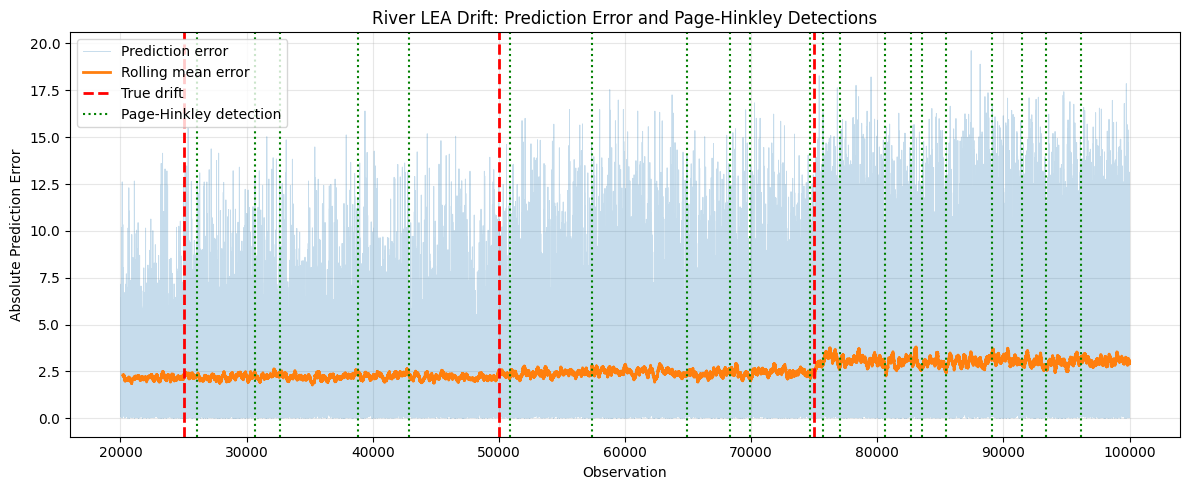

In [116]:
# RIVER BENCHMARK - LEA DRIFT
# Plot prediction errors, rolling mean error, true drift points,
# and Page-Hinkley detections

import matplotlib.pyplot as plt
import pandas as pd

error_series_sudden = pd.Series(
    errors_river_sudden,
    index=range(train_size, len(y_river_sudden))
)

rolling_error_sudden = error_series_sudden.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_sudden.index,
    error_series_sudden.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean error
plt.plot(
    rolling_error_sudden.index,
    rolling_error_sudden.values,
    linewidth=2,
    label="Rolling mean error"
)

# True drift positions
for i, cp in enumerate(cp_river_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# Page-Hinkley detections
for i, cp in enumerate(detected_ph_river_sudden):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="Page-Hinkley detection" if i == 0 else None
    )

plt.title(
    "River LEA Drift: Prediction Error and Page-Hinkley Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# KSWIN

In [118]:
# RIVER BENCHMARK - LEA DRIFT
# Apply KSWIN to the frozen model prediction-error stream
# Use the same error stream used by ADWIN and Page-Hinkley

from river import drift

kswin_river_sudden = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_river_sudden = []

for i, error in enumerate(errors_river_sudden):

    kswin_river_sudden.update(error)

    if kswin_river_sudden.drift_detected:

        # Convert error-stream index back to original River position
        original_position = i + train_size

        detected_kswin_river_sudden.append(
            original_position
        )

print("True changepoints:", cp_river_sudden)
print("KSWIN detected:", detected_kswin_river_sudden)
print(
    "Number of detections:",
    len(detected_kswin_river_sudden)
)

True changepoints: [25000, 50000, 75000]
KSWIN detected: [20909, 22181, 24017, 25664, 26227, 27708, 28204, 28378, 28606, 28731, 28976, 30027, 30272, 30454, 30817, 30995, 33012, 34489, 34789, 35065, 35407, 36886, 37681, 38009, 38457, 38842, 39528, 40102, 40851, 41164, 41748, 42011, 43051, 45252, 45927, 47129, 48337, 48486, 49266, 49458, 49841, 50899, 51501, 52166, 52765, 53507, 53738, 54408, 54917, 57344, 58746, 59616, 63513, 63850, 65129, 65384, 65630, 67457, 67830, 68079, 68233, 68486, 68767, 71554, 71732, 72384, 72764, 72896, 74478, 74876, 76837, 78198, 79425, 81183, 81917, 82138, 82464, 82729, 84942, 85292, 85867, 86688, 87069, 87636, 91973, 93508, 93895, 94020, 94135, 94727, 95084, 95625, 95948, 96137, 96424]
Number of detections: 95


In [119]:
# RIVER BENCHMARK - LEA DRIFT
# Evaluate KSWIN detections against the true changepoints
# Use the same 15,000-observation matching window

import numpy as np

max_delay = 15000

matched_kswin_river_sudden = []
delays_kswin_river_sudden = []

# Match each true drift with the first KSWIN detection after it
for true_cp in cp_river_sudden:

    candidates = [
        d for d in detected_kswin_river_sudden
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_kswin_river_sudden
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_kswin_river_sudden.append(detected_cp)

        delays_kswin_river_sudden.append(
            detected_cp - true_cp
        )

# Detections not matched to a true drift are false alarms
false_alarms_kswin_river_sudden = [
    d for d in detected_kswin_river_sudden
    if d not in matched_kswin_river_sudden
]

# True drifts without a matched detection are missed
missed_kswin_river_sudden = (
    len(cp_river_sudden)
    - len(matched_kswin_river_sudden)
)

# False alarms per 10,000 evaluation observations
false_alarms_per_10k_kswin_river_sudden = (
    len(false_alarms_kswin_river_sudden)
    / len(errors_river_sudden)
    * 10000
)

print("True changepoints:", cp_river_sudden)
print("Matched detections:", matched_kswin_river_sudden)
print("Detection delays:", delays_kswin_river_sudden)
print(
    "Average detection delay:",
    np.mean(delays_kswin_river_sudden)
)
print(
    "Missed detections:",
    missed_kswin_river_sudden
)
print(
    "False alarms:",
    len(false_alarms_kswin_river_sudden)
)
print(
    "False alarms per 10k:",
    false_alarms_per_10k_kswin_river_sudden
)

True changepoints: [25000, 50000, 75000]
Matched detections: [25664, 50899, 76837]
Detection delays: [664, 899, 1837]
Average detection delay: 1133.3333333333333
Missed detections: 0
False alarms: 92
False alarms per 10k: 11.5


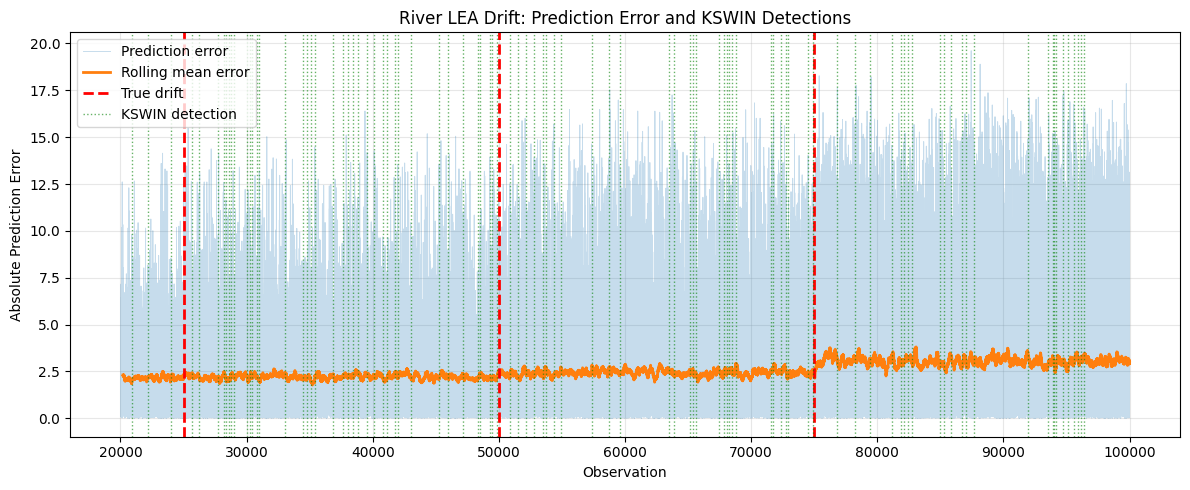

In [120]:
# RIVER BENCHMARK - LEA DRIFT
# Plot prediction errors, rolling mean error, true drift points,
# and KSWIN detections

import matplotlib.pyplot as plt
import pandas as pd

error_series_sudden = pd.Series(
    errors_river_sudden,
    index=range(train_size, len(y_river_sudden))
)

rolling_error_sudden = error_series_sudden.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_sudden.index,
    error_series_sudden.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean error
plt.plot(
    rolling_error_sudden.index,
    rolling_error_sudden.values,
    linewidth=2,
    label="Rolling mean error"
)

# True drift positions
for i, cp in enumerate(cp_river_sudden):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# KSWIN detections
for i, cp in enumerate(detected_kswin_river_sudden):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1,
        alpha=0.6,
        label="KSWIN detection" if i == 0 else None
    )

plt.title(
    "River LEA Drift: Prediction Error and KSWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [121]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Create FriedmanDrift Global Slow Gradual drift generator
# Dataset size target: 100,000 observations
# Gradual transition: approximately 33,333 to 66,666

from river import datasets

river_gradual = datasets.synth.FriedmanDrift(
    drift_type="gsg",
    position=(33333, 66666),
    transition_window=33333,
    seed=42
)

print(river_gradual)

Synthetic data generator

    Name  FriedmanDrift
    Task  Regression   
 Samples  ∞            
Features  10           
  Sparse  False        

Configuration
-------------
       drift_type  gsg           
         position  (33333, 66666)
transition_window  33333         
             seed  42            


# GSG GRADUAL DRIFT

In [122]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Generate 100,000 observations from the FriedmanDrift stream
# Gradual transition: 33,333 to 66,666

X_river_gradual = []
y_river_gradual = []

for x, y in river_gradual.take(100000):
    X_river_gradual.append(x)
    y_river_gradual.append(y)

# Store the known gradual transition boundaries
cp_river_gradual = [33333, 66666]

print("Number of observations:", len(y_river_gradual))
print("Number of features:", len(X_river_gradual[0]))
print("Gradual drift starts:", cp_river_gradual[0])
print("Gradual drift ends:", cp_river_gradual[1])

Number of observations: 100000
Number of features: 10
Gradual drift starts: 33333
Gradual drift ends: 66666


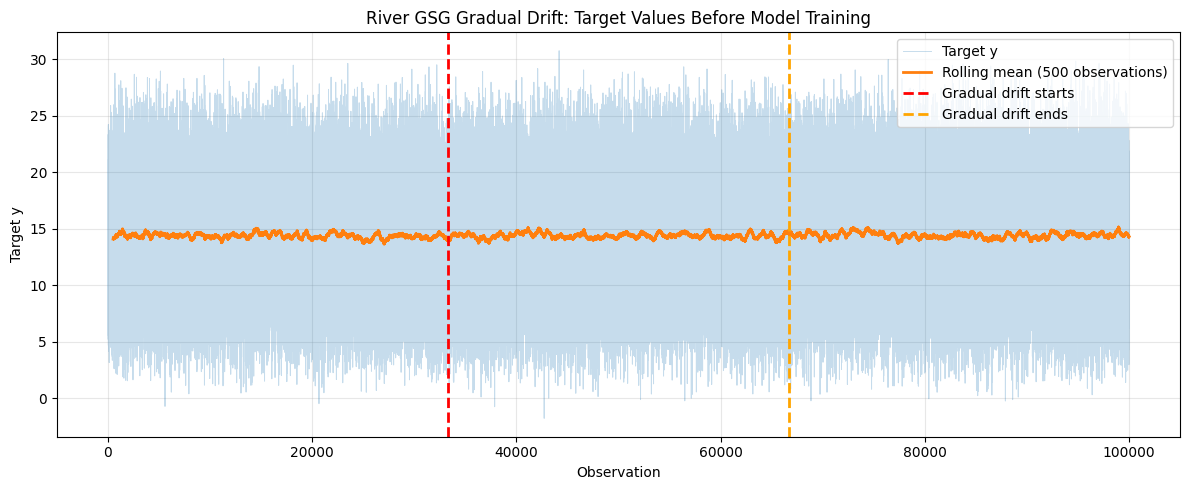

In [123]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Plot the raw target before model training
# Check whether the gradual concept change is visible in y

import matplotlib.pyplot as plt
import pandas as pd

y_river_gradual_series = pd.Series(y_river_gradual)

rolling_y_gradual = y_river_gradual_series.rolling(
    window=500
).mean()

plt.figure(figsize=(12, 5))

# Raw target values
plt.plot(
    y_river_gradual_series,
    alpha=0.25,
    linewidth=0.7,
    label="Target y"
)

# Rolling mean of target
plt.plot(
    rolling_y_gradual,
    linewidth=2,
    label="Rolling mean (500 observations)"
)

# Start of gradual drift
plt.axvline(
    cp_river_gradual[0],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End of gradual drift
plt.axvline(
    cp_river_gradual[1],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

plt.title("River GSG Gradual Drift: Target Values Before Model Training")
plt.xlabel("Observation")
plt.ylabel("Target y")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [125]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Train the regression model using stable pre-drift observations
# Training range: observations 0 to 19,999

from river import linear_model
from river import preprocessing

model_gradual = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression()
)

train_size_gradual = 20000

for i in range(train_size_gradual):
    model_gradual.learn_one(
        X_river_gradual[i],
        y_river_gradual[i]
    )

print("Model trained successfully")
print("Training observations:", train_size_gradual)
print("Gradual drift starts:", cp_river_gradual[0])
print("Gradual drift ends:", cp_river_gradual[1])

Model trained successfully
Training observations: 20000
Gradual drift starts: 33333
Gradual drift ends: 66666


In [126]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Generate prediction errors using the frozen pre-drift model
# Evaluation range: observations 20,000 to 99,999

import numpy as np

actual_gradual = []
predictions_gradual = []
errors_river_gradual = []

for i in range(
    train_size_gradual,
    len(y_river_gradual)
):

    x = X_river_gradual[i]
    y_true = y_river_gradual[i]

    # Predict without updating the model
    y_pred = model_gradual.predict_one(x)

    # Absolute prediction error
    error = abs(y_true - y_pred)

    actual_gradual.append(y_true)
    predictions_gradual.append(y_pred)
    errors_river_gradual.append(error)

# Convert to NumPy arrays
actual_gradual = np.array(actual_gradual)
predictions_gradual = np.array(predictions_gradual)
errors_river_gradual = np.array(errors_river_gradual)

print("Number of predictions:", len(predictions_gradual))
print("First 5 actual values:", actual_gradual[:5])
print("First 5 predictions:", predictions_gradual[:5])
print("First 5 errors:", errors_river_gradual[:5])

Number of predictions: 80000
First 5 actual values: [11.03818182 17.3227348   4.72988675  7.62561812 10.4335413 ]
First 5 predictions: [13.06330474 15.51847023  5.22177357 10.14005584 15.24081403]
First 5 errors: [2.02512292 1.80426457 0.49188682 2.51443772 4.80727272]


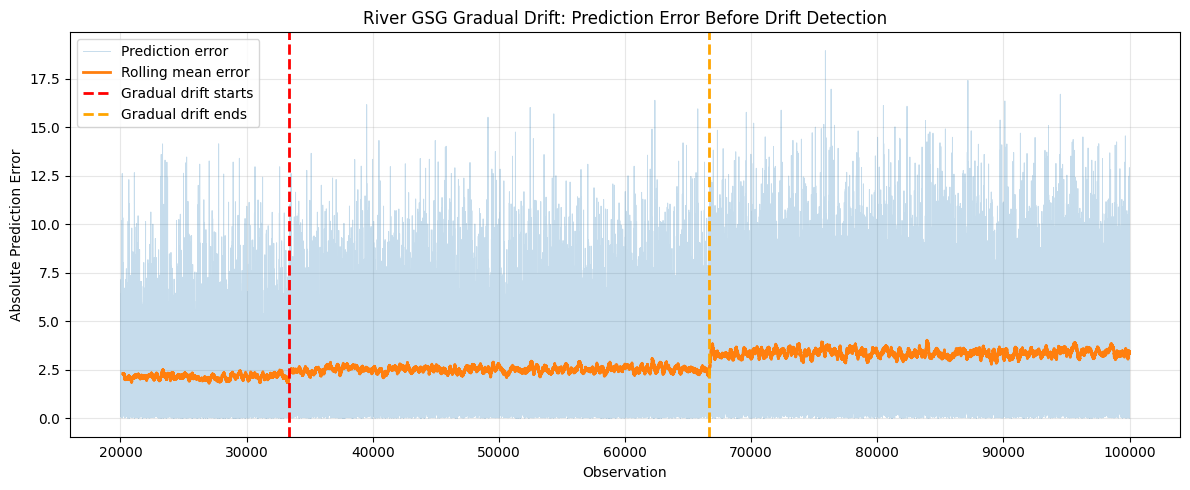

In [127]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Plot prediction errors and rolling mean before applying drift detectors
# Gradual transition: observations 33,333 to 66,666

import matplotlib.pyplot as plt
import pandas as pd

# Put errors on their original River observation positions
error_series_gradual = pd.Series(
    errors_river_gradual,
    index=range(
        train_size_gradual,
        len(y_river_gradual)
    )
)

# Smooth prediction errors for visualization
rolling_error_gradual = error_series_gradual.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_gradual.index,
    error_series_gradual.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_gradual.index,
    rolling_error_gradual.values,
    linewidth=2,
    label="Rolling mean error"
)

# Beginning of gradual drift
plt.axvline(
    cp_river_gradual[0],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End of gradual drift
plt.axvline(
    cp_river_gradual[1],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

plt.title(
    "River GSG Gradual Drift: Prediction Error Before Drift Detection"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ADWIN

In [128]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Apply ADWIN to the frozen model prediction-error stream

from river import drift

adwin_river_gradual = drift.ADWIN()

detected_adwin_river_gradual = []

for i, error in enumerate(errors_river_gradual):

    adwin_river_gradual.update(error)

    if adwin_river_gradual.drift_detected:

        # Convert error-stream index back to original River observation
        original_position = i + train_size_gradual

        detected_adwin_river_gradual.append(
            original_position
        )

print(
    "Gradual drift window:",
    cp_river_gradual[0],
    "to",
    cp_river_gradual[1]
)

print(
    "ADWIN detected:",
    detected_adwin_river_gradual
)

print(
    "Number of detections:",
    len(detected_adwin_river_gradual)
)

Gradual drift window: 33333 to 66666
ADWIN detected: [33887, 66815]
Number of detections: 2


In [129]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Evaluate ADWIN detections within the gradual drift window
# Calculate first detection delay, repeated detections, and false alarms

import numpy as np

gradual_start = cp_river_gradual[0]
gradual_end = cp_river_gradual[1]

# ADWIN detections inside the true gradual drift window
inside_adwin_river_gradual = [
    d for d in detected_adwin_river_gradual
    if gradual_start <= d <= gradual_end
]

# ADWIN detections outside the true gradual drift window
outside_adwin_river_gradual = [
    d for d in detected_adwin_river_gradual
    if d < gradual_start or d > gradual_end
]

# Delay from the start of gradual drift to first valid detection
if len(inside_adwin_river_gradual) > 0:
    first_delay_adwin_river_gradual = (
        inside_adwin_river_gradual[0] - gradual_start
    )
else:
    first_delay_adwin_river_gradual = np.nan

# Did ADWIN detect the gradual drift event?
adwin_river_gradual_detected = (
    1 if len(inside_adwin_river_gradual) > 0 else 0
)

# Was the gradual drift missed?
adwin_river_gradual_missed = (
    0 if adwin_river_gradual_detected == 1 else 1
)

# Detections outside the drift window are false alarms
adwin_river_gradual_false_alarms = len(
    outside_adwin_river_gradual
)

# Additional detections inside the same gradual event
adwin_river_gradual_repeated = max(
    0,
    len(inside_adwin_river_gradual) - 1
)

print(
    "Gradual drift window:",
    gradual_start,
    "to",
    gradual_end
)

print(
    "ADWIN detections:",
    detected_adwin_river_gradual
)

print(
    "Detections inside drift window:",
    inside_adwin_river_gradual
)

print(
    "Detections outside drift window:",
    outside_adwin_river_gradual
)

print(
    "First detection delay:",
    first_delay_adwin_river_gradual
)

print(
    "Missed detections:",
    adwin_river_gradual_missed
)

print(
    "False alarms:",
    adwin_river_gradual_false_alarms
)

print(
    "Repeated detections:",
    adwin_river_gradual_repeated
)

Gradual drift window: 33333 to 66666
ADWIN detections: [33887, 66815]
Detections inside drift window: [33887]
Detections outside drift window: [66815]
First detection delay: 554
Missed detections: 0
False alarms: 1
Repeated detections: 0


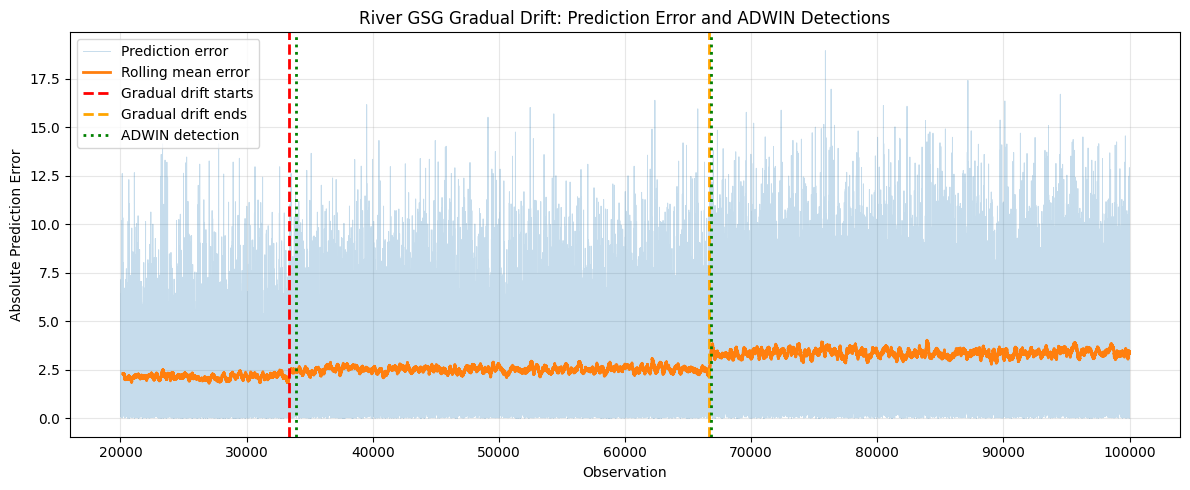

In [130]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Plot prediction errors, rolling mean error, gradual drift window,
# and ADWIN detections

import matplotlib.pyplot as plt
import pandas as pd

error_series_gradual = pd.Series(
    errors_river_gradual,
    index=range(
        train_size_gradual,
        len(y_river_gradual)
    )
)

rolling_error_gradual = error_series_gradual.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_gradual.index,
    error_series_gradual.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_gradual.index,
    rolling_error_gradual.values,
    linewidth=2,
    label="Rolling mean error"
)

# Start of gradual drift
plt.axvline(
    gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End of gradual drift
plt.axvline(
    gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# ADWIN detections
for i, cp in enumerate(detected_adwin_river_gradual):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=2,
        label="ADWIN detection" if i == 0 else None
    )

plt.title(
    "River GSG Gradual Drift: Prediction Error and ADWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Page-Hinkley

In [132]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Apply Page-Hinkley to the frozen model prediction-error stream

from river import drift

ph_river_gradual = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_river_gradual = []

for i, error in enumerate(errors_river_gradual):

    ph_river_gradual.update(error)

    if ph_river_gradual.drift_detected:

        original_position = i + train_size_gradual

        detected_ph_river_gradual.append(
            original_position
        )

print(
    "Gradual drift window:",
    cp_river_gradual[0],
    "to",
    cp_river_gradual[1]
)

print(
    "Page-Hinkley detected:",
    detected_ph_river_gradual
)

print(
    "Number of detections:",
    len(detected_ph_river_gradual)
)

Gradual drift window: 33333 to 66666
Page-Hinkley detected: [27716, 33771, 37166, 40772, 46970, 60461, 63437, 66828, 71895, 74799, 77329, 78136, 85946, 89420, 94785, 99589]
Number of detections: 16


In [133]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Evaluate Page-Hinkley detections around the gradual drift window

import numpy as np

gradual_start = cp_river_gradual[0]
gradual_end = cp_river_gradual[1]

# Detections inside the gradual transition
inside_ph_river_gradual = [
    d for d in detected_ph_river_gradual
    if gradual_start <= d <= gradual_end
]

# Detections before the gradual transition
before_ph_river_gradual = [
    d for d in detected_ph_river_gradual
    if d < gradual_start
]

# Detections after the gradual transition
after_ph_river_gradual = [
    d for d in detected_ph_river_gradual
    if d > gradual_end
]

# Delay from drift start to first detection inside the window
if len(inside_ph_river_gradual) > 0:
    first_delay_ph_river_gradual = (
        inside_ph_river_gradual[0] - gradual_start
    )
else:
    first_delay_ph_river_gradual = np.nan

# Delay of first post-transition detection from the drift end
if len(after_ph_river_gradual) > 0:
    post_transition_delay_ph = (
        after_ph_river_gradual[0] - gradual_end
    )
else:
    post_transition_delay_ph = np.nan

print(
    "Gradual drift window:",
    gradual_start,
    "to",
    gradual_end
)

print(
    "Page-Hinkley detections:",
    detected_ph_river_gradual
)

print(
    "Detections before drift:",
    before_ph_river_gradual
)

print(
    "Detections inside drift window:",
    inside_ph_river_gradual
)

print(
    "Detections after drift:",
    after_ph_river_gradual
)

print(
    "First detection delay:",
    first_delay_ph_river_gradual
)

print(
    "First post-transition delay:",
    post_transition_delay_ph
)

print(
    "Repeated detections inside drift window:",
    max(0, len(inside_ph_river_gradual) - 1)
)

Gradual drift window: 33333 to 66666
Page-Hinkley detections: [27716, 33771, 37166, 40772, 46970, 60461, 63437, 66828, 71895, 74799, 77329, 78136, 85946, 89420, 94785, 99589]
Detections before drift: [27716]
Detections inside drift window: [33771, 37166, 40772, 46970, 60461, 63437]
Detections after drift: [66828, 71895, 74799, 77329, 78136, 85946, 89420, 94785, 99589]
First detection delay: 438
First post-transition delay: 162
Repeated detections inside drift window: 5


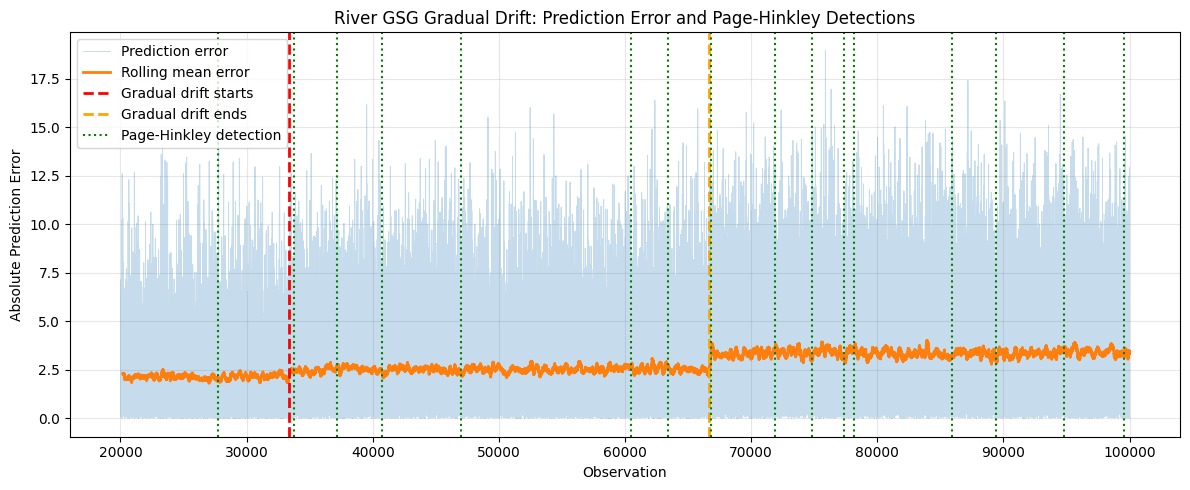

In [134]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Plot prediction errors, rolling mean error, gradual drift window,
# and Page-Hinkley detections

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_gradual.index,
    error_series_gradual.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_gradual.index,
    rolling_error_gradual.values,
    linewidth=2,
    label="Rolling mean error"
)

# Start of gradual drift
plt.axvline(
    gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End of gradual drift
plt.axvline(
    gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# Page-Hinkley detections
for i, cp in enumerate(detected_ph_river_gradual):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="Page-Hinkley detection" if i == 0 else None
    )

plt.title(
    "River GSG Gradual Drift: Prediction Error and Page-Hinkley Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# KSWIN

In [135]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Apply KSWIN to the frozen model prediction-error stream
# Use the same KSWIN parameters used for the LEA experiment

from river import drift

kswin_river_gradual = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_river_gradual = []

for i, error in enumerate(errors_river_gradual):

    kswin_river_gradual.update(error)

    if kswin_river_gradual.drift_detected:

        # Convert error-stream index back to original River observation
        original_position = i + train_size_gradual

        detected_kswin_river_gradual.append(
            original_position
        )

print(
    "Gradual drift window:",
    cp_river_gradual[0],
    "to",
    cp_river_gradual[1]
)

print(
    "KSWIN detected:",
    detected_kswin_river_gradual
)

print(
    "Number of detections:",
    len(detected_kswin_river_gradual)
)

Gradual drift window: 33333 to 66666
KSWIN detected: [20909, 22181, 24017, 25664, 26227, 28370, 28504, 29224, 29699, 30039, 30454, 30817, 30995, 32095, 32978, 33419, 34874, 36481, 37907, 38459, 40688, 41025, 41963, 42743, 43400, 44474, 45024, 45180, 45745, 47645, 48075, 49375, 49841, 50074, 51868, 52607, 53146, 53306, 54461, 54848, 57234, 57476, 58011, 58643, 58916, 59146, 61565, 62397, 63135, 63329, 63486, 65754, 66131, 66642, 67937, 68372, 68790, 69458, 69747, 69941, 70706, 71101, 71437, 71907, 72187, 72677, 73147, 73698, 74719, 74990, 75298, 76885, 77427, 77917, 78081, 79121, 79544, 79703, 82422, 83130, 83759, 85266, 86675, 87931, 88082, 88233, 88585, 88875, 89001, 91013, 93251, 93620, 94230, 94381, 94683, 94852, 95519, 96512, 97910, 98621, 98793]
Number of detections: 101


In [136]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Evaluate KSWIN detections around the gradual drift window

import numpy as np

gradual_start = cp_river_gradual[0]
gradual_end = cp_river_gradual[1]

# Detections before the gradual transition
before_kswin_river_gradual = [
    d for d in detected_kswin_river_gradual
    if d < gradual_start
]

# Detections inside the gradual transition
inside_kswin_river_gradual = [
    d for d in detected_kswin_river_gradual
    if gradual_start <= d <= gradual_end
]

# Detections after the gradual transition
after_kswin_river_gradual = [
    d for d in detected_kswin_river_gradual
    if d > gradual_end
]

# Delay from drift start to first detection inside the window
if len(inside_kswin_river_gradual) > 0:
    first_delay_kswin_river_gradual = (
        inside_kswin_river_gradual[0] - gradual_start
    )
else:
    first_delay_kswin_river_gradual = np.nan

# Delay of first post-transition detection from drift end
if len(after_kswin_river_gradual) > 0:
    post_transition_delay_kswin = (
        after_kswin_river_gradual[0] - gradual_end
    )
else:
    post_transition_delay_kswin = np.nan

# Repeated detections inside the same gradual drift event
repeated_kswin_river_gradual = max(
    0,
    len(inside_kswin_river_gradual) - 1
)

print(
    "Gradual drift window:",
    gradual_start,
    "to",
    gradual_end
)

print(
    "KSWIN detections:",
    detected_kswin_river_gradual
)

print(
    "Detections before drift:",
    before_kswin_river_gradual
)

print(
    "Detections inside drift window:",
    inside_kswin_river_gradual
)

print(
    "Detections after drift:",
    after_kswin_river_gradual
)

print(
    "First detection delay:",
    first_delay_kswin_river_gradual
)

print(
    "First post-transition delay:",
    post_transition_delay_kswin
)

print(
    "Repeated detections inside drift window:",
    repeated_kswin_river_gradual
)

Gradual drift window: 33333 to 66666
KSWIN detections: [20909, 22181, 24017, 25664, 26227, 28370, 28504, 29224, 29699, 30039, 30454, 30817, 30995, 32095, 32978, 33419, 34874, 36481, 37907, 38459, 40688, 41025, 41963, 42743, 43400, 44474, 45024, 45180, 45745, 47645, 48075, 49375, 49841, 50074, 51868, 52607, 53146, 53306, 54461, 54848, 57234, 57476, 58011, 58643, 58916, 59146, 61565, 62397, 63135, 63329, 63486, 65754, 66131, 66642, 67937, 68372, 68790, 69458, 69747, 69941, 70706, 71101, 71437, 71907, 72187, 72677, 73147, 73698, 74719, 74990, 75298, 76885, 77427, 77917, 78081, 79121, 79544, 79703, 82422, 83130, 83759, 85266, 86675, 87931, 88082, 88233, 88585, 88875, 89001, 91013, 93251, 93620, 94230, 94381, 94683, 94852, 95519, 96512, 97910, 98621, 98793]
Detections before drift: [20909, 22181, 24017, 25664, 26227, 28370, 28504, 29224, 29699, 30039, 30454, 30817, 30995, 32095, 32978]
Detections inside drift window: [33419, 34874, 36481, 37907, 38459, 40688, 41025, 41963, 42743, 43400, 444

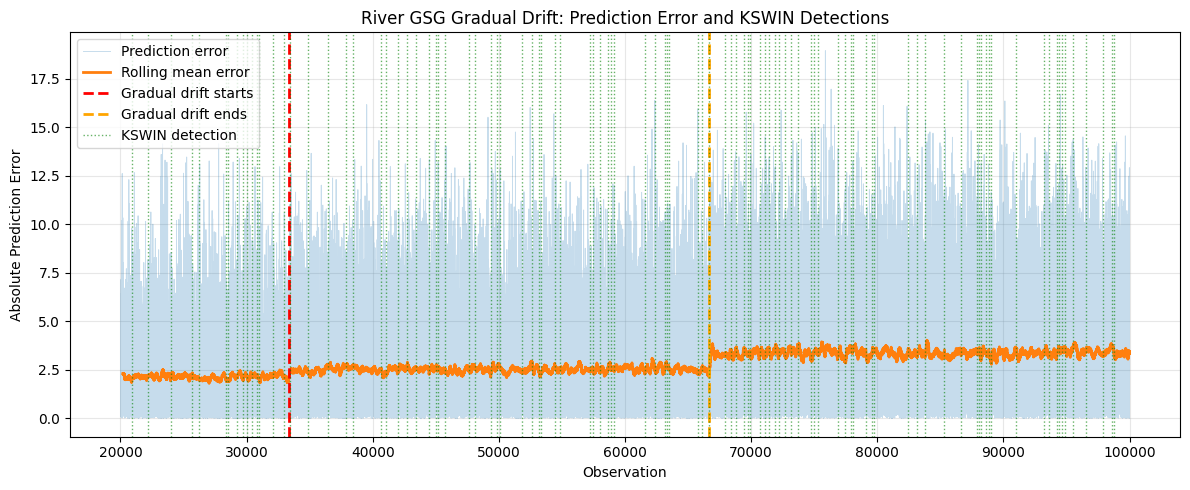

In [137]:
# RIVER BENCHMARK - GSG GRADUAL DRIFT
# Plot prediction errors, rolling mean error, gradual drift window,
# and KSWIN detections

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_gradual.index,
    error_series_gradual.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_gradual.index,
    rolling_error_gradual.values,
    linewidth=2,
    label="Rolling mean error"
)

# Start of gradual drift
plt.axvline(
    gradual_start,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Gradual drift starts"
)

# End of gradual drift
plt.axvline(
    gradual_end,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Gradual drift ends"
)

# KSWIN detections
for i, cp in enumerate(detected_kswin_river_gradual):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1,
        alpha=0.6,
        label="KSWIN detection" if i == 0 else None
    )

plt.title(
    "River GSG Gradual Drift: Prediction Error and KSWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# GRA — Global Recurring Abrupt drift

In [139]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Create FriedmanDrift Global Recurring Abrupt drift generator
# Dataset size target: 100,000 observations
# True changepoints: 33,333 and 66,666

from river import datasets

river_recurring = datasets.synth.FriedmanDrift(
    drift_type="gra",
    position=(33333, 66666),
    seed=42
)

print(river_recurring)

Synthetic data generator

    Name  FriedmanDrift
    Task  Regression   
 Samples  ∞            
Features  10           
  Sparse  False        

Configuration
-------------
       drift_type  gra           
         position  (33333, 66666)
transition_window  10000         
             seed  42            


In [140]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Generate 100,000 observations from the FriedmanDrift stream
# True changepoints: 33,333 and 66,666

X_river_recurring = []
y_river_recurring = []

for x, y in river_recurring.take(100000):
    X_river_recurring.append(x)
    y_river_recurring.append(y)

# Store the known true changepoints
cp_river_recurring = [33333, 66666]

print("Number of observations:", len(y_river_recurring))
print("Number of features:", len(X_river_recurring[0]))
print("True changepoints:", cp_river_recurring)

Number of observations: 100000
Number of features: 10
True changepoints: [33333, 66666]


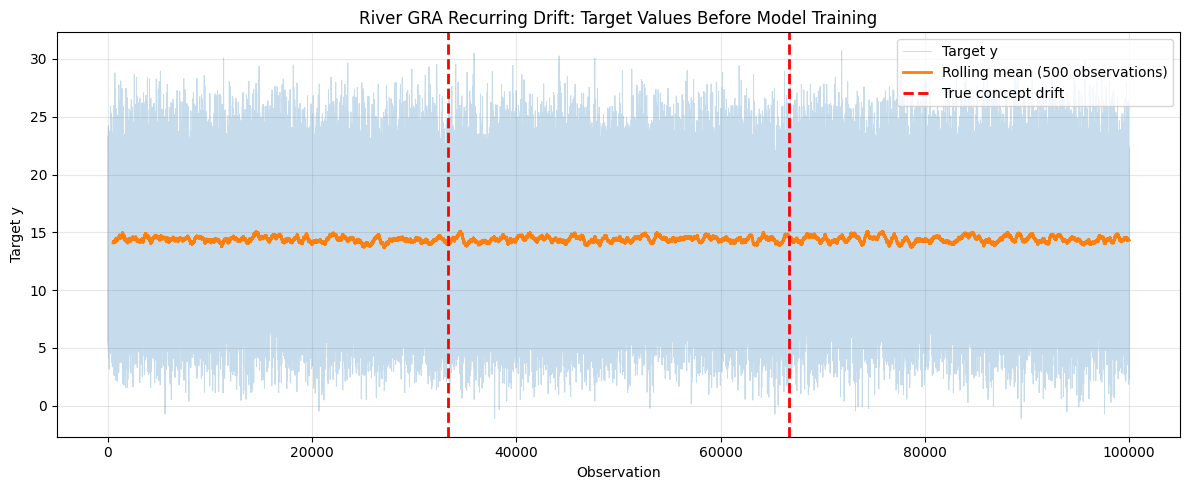

In [141]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Plot the raw target before model training
# Check whether recurring concept changes are directly visible in y

import matplotlib.pyplot as plt
import pandas as pd

y_river_recurring_series = pd.Series(y_river_recurring)

rolling_y_recurring = y_river_recurring_series.rolling(
    window=500
).mean()

plt.figure(figsize=(12, 5))

# Raw target values
plt.plot(
    y_river_recurring_series,
    alpha=0.25,
    linewidth=0.7,
    label="Target y"
)

# Rolling mean of target
plt.plot(
    rolling_y_recurring,
    linewidth=2,
    label="Rolling mean (500 observations)"
)

# True changepoints
for i, cp in enumerate(cp_river_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True concept drift" if i == 0 else None
    )

plt.title("River GRA Recurring Drift: Target Values Before Model Training")
plt.xlabel("Observation")
plt.ylabel("Target y")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [142]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Train the regression model using stable pre-drift observations
# Training range: observations 0 to 19,999

from river import linear_model
from river import preprocessing

model_recurring = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression()
)

train_size_recurring = 20000

for i in range(train_size_recurring):
    model_recurring.learn_one(
        X_river_recurring[i],
        y_river_recurring[i]
    )

print("Model trained successfully")
print("Training observations:", train_size_recurring)
print("First true drift:", cp_river_recurring[0])
print("Second true drift:", cp_river_recurring[1])

Model trained successfully
Training observations: 20000
First true drift: 33333
Second true drift: 66666


In [143]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Generate prediction errors using the frozen pre-drift model
# Evaluation range: observations 20,000 to 99,999

import numpy as np

actual_recurring = []
predictions_recurring = []
errors_river_recurring = []

for i in range(
    train_size_recurring,
    len(y_river_recurring)
):

    x = X_river_recurring[i]
    y_true = y_river_recurring[i]

    # Predict without updating the model
    y_pred = model_recurring.predict_one(x)

    # Absolute prediction error
    error = abs(y_true - y_pred)

    actual_recurring.append(y_true)
    predictions_recurring.append(y_pred)
    errors_river_recurring.append(error)

# Convert to NumPy arrays
actual_recurring = np.array(actual_recurring)
predictions_recurring = np.array(predictions_recurring)
errors_river_recurring = np.array(errors_river_recurring)

print("Number of predictions:", len(predictions_recurring))
print("First 5 actual values:", actual_recurring[:5])
print("First 5 predictions:", predictions_recurring[:5])
print("First 5 errors:", errors_river_recurring[:5])

Number of predictions: 80000
First 5 actual values: [11.03818182 17.3227348   4.72988675  7.62561812 10.4335413 ]
First 5 predictions: [13.06330474 15.51847023  5.22177357 10.14005584 15.24081403]
First 5 errors: [2.02512292 1.80426457 0.49188682 2.51443772 4.80727272]


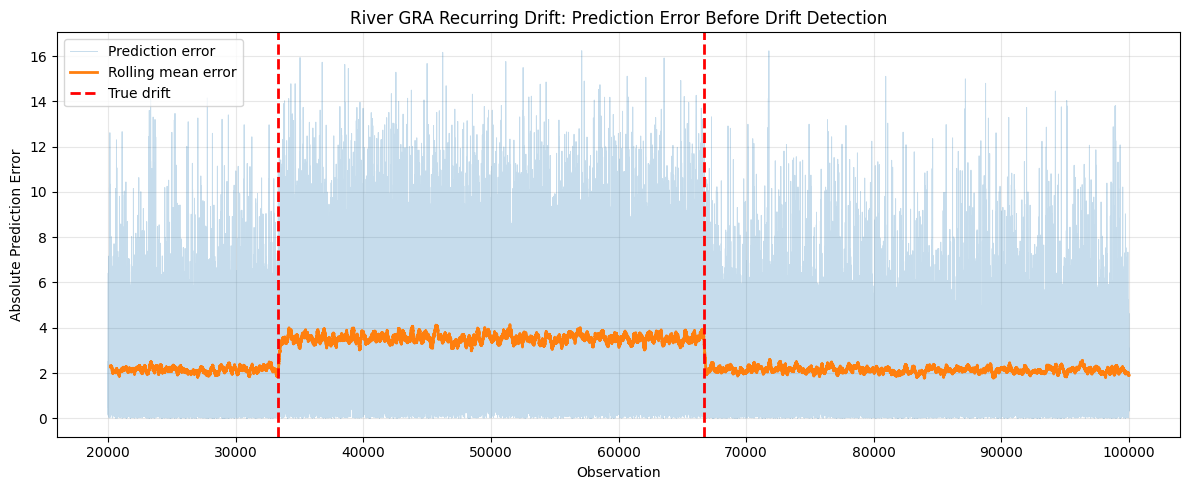

In [144]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Plot prediction errors and rolling mean before applying drift detectors
# Concept A changes to B at 33,333 and Concept A returns at 66,666

import matplotlib.pyplot as plt
import pandas as pd

# Put prediction errors on their original River observation positions
error_series_recurring = pd.Series(
    errors_river_recurring,
    index=range(
        train_size_recurring,
        len(y_river_recurring)
    )
)

# Smooth prediction errors for visualization
rolling_error_recurring = error_series_recurring.rolling(
    window=200
).mean()

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_recurring.index,
    error_series_recurring.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_recurring.index,
    rolling_error_recurring.values,
    linewidth=2,
    label="Rolling mean error"
)

# True recurring drift positions
for i, cp in enumerate(cp_river_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

plt.title(
    "River GRA Recurring Drift: Prediction Error Before Drift Detection"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ADWIN

In [145]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Apply ADWIN to the frozen model prediction-error stream

from river import drift

adwin_river_recurring = drift.ADWIN()

detected_adwin_river_recurring = []

for i, error in enumerate(errors_river_recurring):

    adwin_river_recurring.update(error)

    if adwin_river_recurring.drift_detected:

        # Convert error-stream index back to original River observation
        original_position = i + train_size_recurring

        detected_adwin_river_recurring.append(
            original_position
        )

print("True changepoints:", cp_river_recurring)
print("ADWIN detected:", detected_adwin_river_recurring)
print(
    "Number of detections:",
    len(detected_adwin_river_recurring)
)

True changepoints: [33333, 66666]
ADWIN detected: [33375, 66783]
Number of detections: 2


In [146]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Evaluate ADWIN detections against the true changepoints
# Calculate detection delay, missed detections, and false alarms

import numpy as np

max_delay = 15000

matched_adwin_river_recurring = []
delays_adwin_river_recurring = []

for true_cp in cp_river_recurring:

    candidates = [
        d for d in detected_adwin_river_recurring
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_adwin_river_recurring
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_adwin_river_recurring.append(detected_cp)

        delays_adwin_river_recurring.append(
            detected_cp - true_cp
        )

# Detections not matched to a true drift are false alarms
false_alarms_adwin_river_recurring = [
    d for d in detected_adwin_river_recurring
    if d not in matched_adwin_river_recurring
]

# True drifts without a matched detection are missed
missed_adwin_river_recurring = (
    len(cp_river_recurring)
    - len(matched_adwin_river_recurring)
)

# False alarms per 10,000 evaluation observations
false_alarms_per_10k_adwin_recurring = (
    len(false_alarms_adwin_river_recurring)
    / len(errors_river_recurring)
    * 10000
)

print("True changepoints:", cp_river_recurring)
print("Matched detections:", matched_adwin_river_recurring)
print("Detection delays:", delays_adwin_river_recurring)
print(
    "Average detection delay:",
    np.mean(delays_adwin_river_recurring)
)
print(
    "Missed detections:",
    missed_adwin_river_recurring
)
print(
    "False alarms:",
    len(false_alarms_adwin_river_recurring)
)
print(
    "False alarms per 10k:",
    false_alarms_per_10k_adwin_recurring
)

True changepoints: [33333, 66666]
Matched detections: [33375, 66783]
Detection delays: [42, 117]
Average detection delay: 79.5
Missed detections: 0
False alarms: 0
False alarms per 10k: 0.0


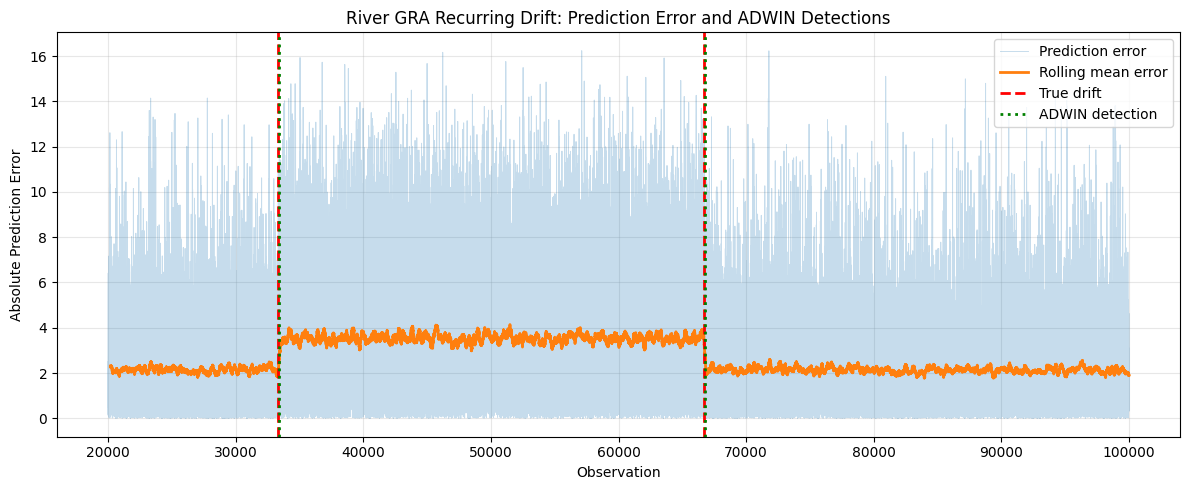

In [147]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Plot prediction errors, rolling mean error, true changepoints,
# and ADWIN detections

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_recurring.index,
    error_series_recurring.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_recurring.index,
    rolling_error_recurring.values,
    linewidth=2,
    label="Rolling mean error"
)

# True changepoints
for i, cp in enumerate(cp_river_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# ADWIN detections
for i, cp in enumerate(detected_adwin_river_recurring):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=2,
        label="ADWIN detection" if i == 0 else None
    )

plt.title(
    "River GRA Recurring Drift: Prediction Error and ADWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Page-Hinkley

In [148]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Apply Page-Hinkley to the frozen model prediction-error stream

from river import drift

ph_river_recurring = drift.PageHinkley(
    min_instances=100,
    delta=0.01,
    threshold=200
)

detected_ph_river_recurring = []

for i, error in enumerate(errors_river_recurring):

    ph_river_recurring.update(error)

    if ph_river_recurring.drift_detected:

        # Convert error-stream index back to original River observation
        original_position = i + train_size_recurring

        detected_ph_river_recurring.append(
            original_position
        )

print("True changepoints:", cp_river_recurring)
print("Page-Hinkley detected:", detected_ph_river_recurring)
print(
    "Number of detections:",
    len(detected_ph_river_recurring)
)

True changepoints: [33333, 66666]
Page-Hinkley detected: [27716, 33433, 44402, 47293, 49598, 53286, 56804, 61041, 66776, 81622, 87332, 96333]
Number of detections: 12


In [149]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Evaluate Page-Hinkley detections against the true changepoints
# Calculate detection delay, missed detections, and false alarms

import numpy as np

max_delay = 15000

matched_ph_river_recurring = []
delays_ph_river_recurring = []

# Match each true drift with the first Page-Hinkley detection after it
for true_cp in cp_river_recurring:

    candidates = [
        d for d in detected_ph_river_recurring
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_ph_river_recurring
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_ph_river_recurring.append(detected_cp)

        delays_ph_river_recurring.append(
            detected_cp - true_cp
        )

# Detections not matched to a true drift are false alarms
false_alarms_ph_river_recurring = [
    d for d in detected_ph_river_recurring
    if d not in matched_ph_river_recurring
]

# True drifts without a matched detection are missed
missed_ph_river_recurring = (
    len(cp_river_recurring)
    - len(matched_ph_river_recurring)
)

# False alarms per 10,000 evaluation observations
false_alarms_per_10k_ph_recurring = (
    len(false_alarms_ph_river_recurring)
    / len(errors_river_recurring)
    * 10000
)

print("True changepoints:", cp_river_recurring)
print("Matched detections:", matched_ph_river_recurring)
print("Detection delays:", delays_ph_river_recurring)
print(
    "Average detection delay:",
    np.mean(delays_ph_river_recurring)
)
print(
    "Missed detections:",
    missed_ph_river_recurring
)
print(
    "False alarms:",
    len(false_alarms_ph_river_recurring)
)
print(
    "False alarms per 10k:",
    false_alarms_per_10k_ph_recurring
)

True changepoints: [33333, 66666]
Matched detections: [33433, 66776]
Detection delays: [100, 110]
Average detection delay: 105.0
Missed detections: 0
False alarms: 10
False alarms per 10k: 1.25


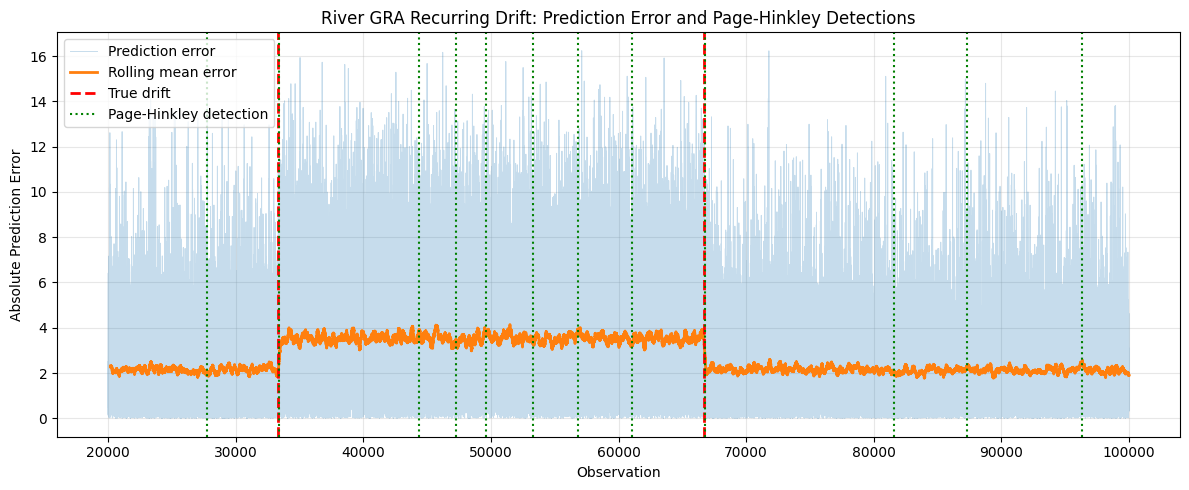

In [150]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Plot prediction errors, rolling mean error, true changepoints,
# and Page-Hinkley detections

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_recurring.index,
    error_series_recurring.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_recurring.index,
    rolling_error_recurring.values,
    linewidth=2,
    label="Rolling mean error"
)

# True changepoints
for i, cp in enumerate(cp_river_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# Page-Hinkley detections
for i, cp in enumerate(detected_ph_river_recurring):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1.5,
        label="Page-Hinkley detection" if i == 0 else None
    )

plt.title(
    "River GRA Recurring Drift: Prediction Error and Page-Hinkley Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# KSWIN

In [151]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Apply KSWIN to the frozen model prediction-error stream
# Use the same KSWIN parameters as LEA and GSG

from river import drift

kswin_river_recurring = drift.KSWIN(
    alpha=0.005,
    window_size=100,
    stat_size=30,
    seed=42
)

detected_kswin_river_recurring = []

for i, error in enumerate(errors_river_recurring):

    kswin_river_recurring.update(error)

    if kswin_river_recurring.drift_detected:

        # Convert error-stream index back to original River observation
        original_position = i + train_size_recurring

        detected_kswin_river_recurring.append(
            original_position
        )

print("True changepoints:", cp_river_recurring)
print("KSWIN detected:", detected_kswin_river_recurring)
print(
    "Number of detections:",
    len(detected_kswin_river_recurring)
)

True changepoints: [33333, 66666]
KSWIN detected: [20909, 22181, 24017, 25664, 26227, 28370, 28504, 29224, 29699, 30039, 30454, 30817, 30995, 32095, 32978, 33750, 34207, 35217, 35979, 38131, 38461, 39163, 39565, 39784, 40826, 41441, 41931, 42556, 44688, 46785, 47116, 48493, 49157, 49349, 50043, 50561, 51411, 51943, 53501, 53886, 54359, 56414, 59277, 59737, 59864, 60343, 60446, 60991, 61260, 61530, 61767, 62133, 62247, 63162, 63967, 64983, 65201, 65503, 65783, 66250, 66587, 66713, 66861, 67828, 68232, 69365, 70005, 71171, 71631, 73720, 75295, 76829, 78190, 78739, 79214, 79753, 80219, 81103, 81529, 82148, 82374, 82512, 83014, 83746, 84361, 84871, 85084, 85260, 85363, 85506, 86529, 86763, 87039, 87444, 87940, 88836, 89261, 89539, 90056, 90215, 92294, 93378, 93681, 93893, 95333, 95548, 96133, 98209, 98461]
Number of detections: 109


In [152]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Evaluate KSWIN detections against the true changepoints
# Calculate detection delay, missed detections, and false alarms

import numpy as np

max_delay = 15000

matched_kswin_river_recurring = []
delays_kswin_river_recurring = []

# Match each true drift with the first KSWIN detection after it
for true_cp in cp_river_recurring:

    candidates = [
        d for d in detected_kswin_river_recurring
        if true_cp <= d <= true_cp + max_delay
        and d not in matched_kswin_river_recurring
    ]

    if candidates:
        detected_cp = candidates[0]

        matched_kswin_river_recurring.append(
            detected_cp
        )

        delays_kswin_river_recurring.append(
            detected_cp - true_cp
        )

# Detections not matched to a true drift are false alarms
false_alarms_kswin_river_recurring = [
    d for d in detected_kswin_river_recurring
    if d not in matched_kswin_river_recurring
]

# True drifts without a matched detection are missed
missed_kswin_river_recurring = (
    len(cp_river_recurring)
    - len(matched_kswin_river_recurring)
)

# False alarms per 10,000 evaluation observations
false_alarms_per_10k_kswin_recurring = (
    len(false_alarms_kswin_river_recurring)
    / len(errors_river_recurring)
    * 10000
)

print("True changepoints:", cp_river_recurring)
print("Matched detections:", matched_kswin_river_recurring)
print("Detection delays:", delays_kswin_river_recurring)
print(
    "Average detection delay:",
    np.mean(delays_kswin_river_recurring)
)
print(
    "Missed detections:",
    missed_kswin_river_recurring
)
print(
    "False alarms:",
    len(false_alarms_kswin_river_recurring)
)
print(
    "False alarms per 10k:",
    false_alarms_per_10k_kswin_recurring
)

True changepoints: [33333, 66666]
Matched detections: [33750, 66713]
Detection delays: [417, 47]
Average detection delay: 232.0
Missed detections: 0
False alarms: 107
False alarms per 10k: 13.375


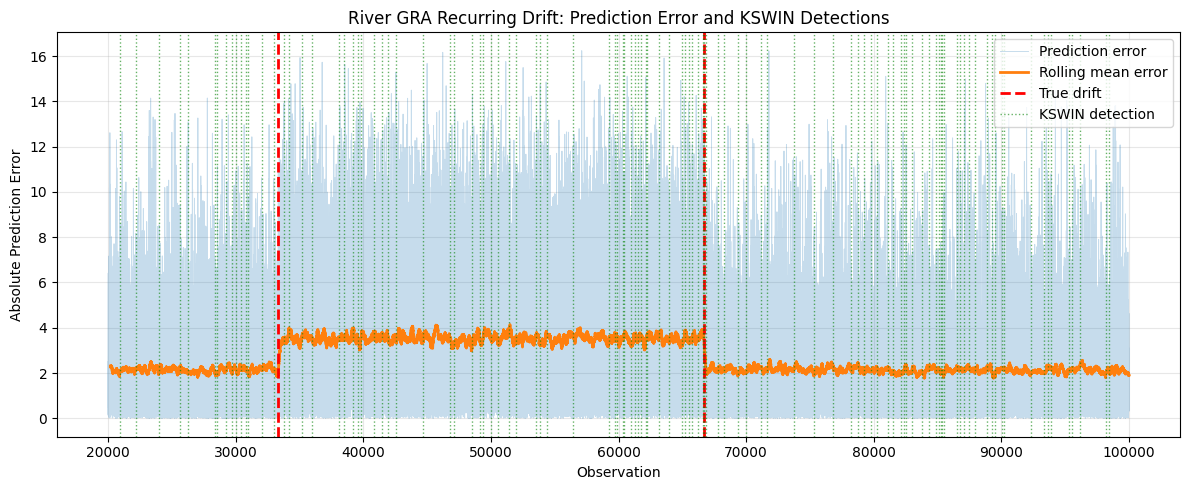

In [153]:
# RIVER BENCHMARK - GRA RECURRING ABRUPT DRIFT
# Plot prediction errors, rolling mean error, true changepoints,
# and KSWIN detections

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Raw prediction errors
plt.plot(
    error_series_recurring.index,
    error_series_recurring.values,
    alpha=0.25,
    linewidth=0.7,
    label="Prediction error"
)

# Rolling mean prediction error
plt.plot(
    rolling_error_recurring.index,
    rolling_error_recurring.values,
    linewidth=2,
    label="Rolling mean error"
)

# True changepoints
for i, cp in enumerate(cp_river_recurring):
    plt.axvline(
        cp,
        color="red",
        linestyle="--",
        linewidth=2,
        label="True drift" if i == 0 else None
    )

# KSWIN detections
for i, cp in enumerate(detected_kswin_river_recurring):
    plt.axvline(
        cp,
        color="green",
        linestyle=":",
        linewidth=1,
        alpha=0.6,
        label="KSWIN detection" if i == 0 else None
    )

plt.title(
    "River GRA Recurring Drift: Prediction Error and KSWIN Detections"
)
plt.xlabel("Observation")
plt.ylabel("Absolute Prediction Error")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [155]:
# RIVER BENCHMARK - FINAL RESULTS TABLE
# Build the summary directly from the calculated experiment variables

import pandas as pd
import numpy as np

river_results = pd.DataFrame({

    "Detector": [
        "ADWIN", "Page-Hinkley", "KSWIN",
        "ADWIN", "Page-Hinkley", "KSWIN",
        "ADWIN", "Page-Hinkley", "KSWIN"
    ],

    "Drift Type": [
        "LEA", "LEA", "LEA",
        "GSG", "GSG", "GSG",
        "GRA", "GRA", "GRA"
    ],

    "True Drift Events": [
        len(cp_river_sudden),
        len(cp_river_sudden),
        len(cp_river_sudden),

        1,
        1,
        1,

        len(cp_river_recurring),
        len(cp_river_recurring),
        len(cp_river_recurring)
    ],

    "Detected Events": [
        len(matched_adwin_river_sudden),
        len(matched_ph_river_sudden),
        len(matched_kswin_river_sudden),

        int(len(inside_adwin_river_gradual) > 0),
        int(len(inside_ph_river_gradual) > 0),
        int(len(inside_kswin_river_gradual) > 0),

        len(matched_adwin_river_recurring),
        len(matched_ph_river_recurring),
        len(matched_kswin_river_recurring)
    ],

    "Detection Delay": [
        np.mean(delays_adwin_river_sudden),
        np.mean(delays_ph_river_sudden),
        np.mean(delays_kswin_river_sudden),

        first_delay_adwin_river_gradual,
        first_delay_ph_river_gradual,
        first_delay_kswin_river_gradual,

        np.mean(delays_adwin_river_recurring),
        np.mean(delays_ph_river_recurring),
        np.mean(delays_kswin_river_recurring)
    ],

    "Missed Detections": [
        missed_adwin_river_sudden,
        missed_ph_river_sudden,
        missed_kswin_river_sudden,

        int(len(inside_adwin_river_gradual) == 0),
        int(len(inside_ph_river_gradual) == 0),
        int(len(inside_kswin_river_gradual) == 0),

        missed_adwin_river_recurring,
        missed_ph_river_recurring,
        missed_kswin_river_recurring
    ],

    "False Alarms": [
        len(false_alarms_adwin_river_sudden),
        len(false_alarms_ph_river_sudden),
        len(false_alarms_kswin_river_sudden),

        len([
            d for d in detected_adwin_river_gradual
            if d < gradual_start
        ]),
        len(before_ph_river_gradual),
        len(before_kswin_river_gradual),

        len(false_alarms_adwin_river_recurring),
        len(false_alarms_ph_river_recurring),
        len(false_alarms_kswin_river_recurring)
    ],

    "Repeated Detections": [
        0,
        0,
        0,

        max(0, len(inside_adwin_river_gradual) - 1),
        max(0, len(inside_ph_river_gradual) - 1),
        max(0, len(inside_kswin_river_gradual) - 1),

        0,
        0,
        0
    ]
})

# Calculate false alarms per 10,000 observations automatically
river_results["False Alarms per 10k"] = (
    river_results["False Alarms"]
    / len(errors_river_sudden)
    * 10000
)

river_results

,Detector,Drift Type,True Drift Events,Detected Events,Detection Delay,Missed Detections,False Alarms,Repeated Detections,False Alarms per 10k
0,ADWIN,LEA,3,3,4761.666667,0,0,0,0.000
1,Page-Hinkley,LEA,3,3,891.000000,0,18,0,2.250
2,KSWIN,LEA,3,3,1133.333333,0,92,0,11.500
3,ADWIN,GSG,1,1,554.000000,0,0,0,0.000
4,Page-Hinkley,GSG,1,1,438.000000,0,1,5,0.125
5,KSWIN,GSG,1,1,86.000000,0,15,38,1.875
6,ADWIN,GRA,2,2,79.500000,0,0,0,0.000
7,Page-Hinkley,GRA,2,2,105.000000,0,10,0,1.250
8,KSWIN,GRA,2,2,232.000000,0,107,0,13.375


### River Benchmark Analysis

The River benchmark shows clear differences between ADWIN, Page-Hinkley, and KSWIN across the LEA, GSG, and GRA drift scenarios. All three detectors successfully detected every true drift event, with **zero missed detections**, but they differed substantially in detection delay and false-alarm behaviour.

**ADWIN** was the most conservative and reliable detector overall. For LEA, it detected all three drift events with **zero false alarms**, although its average detection delay was relatively high at **4,761.67 observations**. Its performance improved considerably for GSG, where the gradual drift was first detected after **554 observations**, again without false alarms or repeated detections. ADWIN performed particularly strongly on GRA, detecting both recurring abrupt changes with an average delay of only **79.5 observations** and **zero false alarms**. This indicates that ADWIN was highly effective when the drift produced a strong change in the model's prediction-error distribution, while weaker LEA changes required considerably more evidence before an alarm was raised.

**Page-Hinkley** generally detected changes faster than ADWIN in LEA and GSG, but this increased sensitivity came at the cost of additional alarms. For LEA, its average delay was **891 observations**, substantially lower than ADWIN's, but it generated **18 false alarms (2.25 per 10,000 observations)**. For GSG, Page-Hinkley detected the gradual transition after **438 observations**, with **1 pre-drift false alarm** and **5 repeated detections during the same gradual-drift event**. On GRA, it detected both true changes with an average delay of **105 observations**, but generated **10 false alarms**. Page-Hinkley therefore provides a stronger balance between detection speed and alarm frequency than KSWIN, although it is less conservative than ADWIN.

**KSWIN** was the most sensitive detector. It detected the GSG transition after only **86 observations**, making it the fastest detector for this scenario. However, this sensitivity resulted in substantial over-detection. It produced **92 false alarms for LEA**, **15 pre-drift false alarms and 38 repeated detections for GSG**, and **107 false alarms for GRA**. Its false-alarm rates reached **11.5 and 13.375 per 10,000 observations** for LEA and GRA respectively. Therefore, although KSWIN can react very quickly to distributional changes, its current configuration produces too many additional alarms to be considered reliable based on detection delay alone.

Overall, the experiment demonstrates an important **sensitivity–stability trade-off**. ADWIN provides the greatest stability and lowest false-alarm rate, Page-Hinkley provides faster detection at the cost of moderate additional alarms, and KSWIN provides high sensitivity but substantially more false and repeated detections. The results also demonstrate that detector performance depends strongly on the type and strength of concept drift: the same detector can behave very differently across LEA, GSG, and GRA prediction-error streams.

These results represent a **single River benchmark run with the current stream configuration and random seed**. Therefore, they should be interpreted as preliminary comparative results rather than evidence that one detector is universally superior. Repeating the experiments across multiple random seeds will provide a more robust estimate of each detector's detection delay, false-alarm rate, and overall stability.

# How do the detectors behave as the exact same drift becomes slower or more gradual?